# ParaDetox — Toxic-to-Neutral Text Paraphrase Generation Using Encoder–Decoder Architectures

**NLP Course Project | Master 2 Artificial Intelligence & Data Science**  
**Université Paris Dauphine–PSL**  
**ROMDHANI Soumaya**

---

## Project Overview

This project investigates **toxic-to-neutral text generation** as a sequence-to-sequence learning task. The objective is to automatically reformulate toxic or offensive sentences into neutral expressions while preserving their original meaning, grammatical correctness, and essential information.

The study focuses on the **implementation, training, and evaluation of neural Encoder–Decoder architectures from scratch using PyTorch**, in accordance with the NLP course requirements.

Three architectures are investigated and compared:

- **LSTM Encoder–Decoder:** a baseline sequence-generation model.
- **LSTM Encoder–Decoder with Attention:** an enhanced architecture that dynamically focuses on relevant source tokens.
- **LSTM with Attention and Pointer Mechanism:** an extension designed to facilitate the preservation of important source information.

The project also examines **teacher forcing, scheduled sampling, greedy decoding, beam search, and constrained candidate reranking**.

## Methodology and Evaluation

The experiments are conducted using the **ParaDetox dataset**, containing paired toxic and neutral sentences.

The notebook presents the complete experimental pipeline, including data exploration, preprocessing, tokenization, vocabulary construction, model implementation, training, validation, inference, and comparative evaluation.

Model performance is assessed through quantitative metrics, including **BLEU, chrF, toxicity estimation, semantic similarity, and information-preservation indicators**, complemented by a qualitative analysis of generated sentences.

Both successful generations and representative failure cases are examined to identify architectural strengths, limitations, and potential improvements.

## Execution and Reproducibility

This notebook contains **the recorded outputs of a completed Google Colab execution**, including training curves, evaluation metrics, model comparisons, and generated examples.

The implementation is provided in readable, executable Python cells. Model checkpoints are not embedded in the notebook; consequently, executing it in a new environment requires training the models again.

For reproduction:

1. Open the notebook in **Google Colab** and enable a GPU runtime when available.
2. Select **Runtime → Run all** to execute the complete pipeline.
3. Use the final inference section to evaluate the model on additional input sentences.

The reported results correspond to the recorded experimental execution. Differences may occur when retraining the models in another environment.

---

**Project scope:** End-to-end neural text generation, experimental comparison, quantitative evaluation, qualitative error analysis, and critical discussion of the limitations of from-scratch Encoder–Decoder models.

## Sommaire · Les 20 exigences du sujet

| Partie | Sections |
|:--|:--|
| **Problème et données** | [1. Objectif général](#part-01) · [2. Choix de la tâche](#part-02) · [3. Architecture générale](#part-03) · [4. Implémentation depuis zéro](#part-04) · [5. Jeu de données](#part-05) · [6. Prétraitement des textes](#part-06) · [7. Représentation des tokens](#part-07) |
| **Architecture et apprentissage** | [8. Encodeur](#part-08) · [9. Décodeur](#part-09) · [10. Teacher forcing](#part-10) · [11. Mécanisme d’attention](#part-11) · [12. Entraînement](#part-12) |
| **Génération et évaluation** | [13. Génération et inférence](#part-13) · [14. Stratégies de décodage](#part-14) · [15. Évaluation](#part-15) · [16. Comparaison des architectures](#part-16) · [17. Analyse critique des résultats](#part-17) |
| **Synthèse et conformité** | [18. Synthèse du projet](#part-18) · [19. Vérification des exigences](#part-19) · [20. Limites et conclusions](#part-20) |

*Les intitulés anglais du document de la professeure restent indiqués en sous-titre dans chaque section.*


In [1]:
# Configuration générale — seule cellule à modifier pour ajuster les expériences.
SEED = 42
USE_GPU = True
TRAIN_EXTENDED_ATTENTION = True  # expérience complémentaire, au-delà du budget égal de 12 époques

# Téléchargements uniquement pour les bibliothèques qui manquent à Colab.
import importlib.util, subprocess, sys, os, tempfile
from pathlib import Path
packages = {
    'torch': 'torch>=2.6,<3', 'numpy': 'numpy>=1.26,<3',
    'pandas': 'pandas>=2.1,<4', 'sentencepiece': 'sentencepiece>=0.2,<0.3',
    'sacrebleu': 'sacrebleu>=2.4,<3', 'matplotlib': 'matplotlib>=3.8,<4',
    'transformers': 'transformers>=4.40,<6',
    'sentence_transformers': 'sentence-transformers>=3,<7',
    'ipywidgets': 'ipywidgets>=8,<9',
}
missing = [spec for module, spec in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
ROOT = Path('/content/paradetox_colab_qualite_v3') if Path('/content').exists() else Path(tempfile.gettempdir())/'paradetox_colab_qualite_v3'
ROOT.mkdir(parents=True, exist_ok=True)
os.chdir(ROOT)

In [2]:
import copy, hashlib, json, math, random, re, time, unicodedata, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
import sentencepiece as spm
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import Dataset, DataLoader
from sacrebleu.metrics import BLEU, CHRF
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
DEVICE=torch.device('cuda' if USE_GPU and torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
PAD, UNK, BOS, EOS = 0, 1, 2, 3
IMPLEMENTATION_VERSION='paradetox-visible-lstm-v3-20261031'  # identifiant de version, PAS un hash du code
print('Appareil :',DEVICE,'| PyTorch :',torch.__version__)
if DEVICE.type=='cpu':
    print('CPU compatible : évaluateurs et beam search plus lents ; le réentraînement peut prendre des heures.')
else:
    print('GPU :',torch.cuda.get_device_name(0))
print('Mode : entraînement depuis zéro ; reprises locales si disponibles.')

Appareil : cuda | PyTorch : 2.11.0+cu130
GPU : Tesla T4
Mode : entraînement depuis zéro ; reprises locales si disponibles.


<a id="part-01"></a>
## 1. Objectif général

*General objective*

Réécrire une entrée toxique $x$ en une sortie $y$ moins offensante, en conservant le sens.
On apprend $p_\theta(y\mid x)=\prod_t p_\theta(y_t\mid y_{<t},x)$ avec des paires supervisées.
La qualité ne se réduit pas à BLEU : **style, sens, grammaire et faits** peuvent évoluer différemment.
Le but pédagogique est de comprendre chaque transformation, du texte à la génération.

<a id="part-02"></a>
## 2. Choix de la tâche

*Choice of task*

La détoxification est une paraphrase contrainte, en anglais. Les explications sont en français.
Une référence du corpus est une reformulation possible, pas une unique réponse vraie ; certaines
références omettent des faits ou sont peu naturelles. Les cas libres n’ont pas de référence inventée.
Source : [ParaDetox, Logacheva et al., ACL 2022](https://aclanthology.org/2022.acl-long.469/).
Le statut d’approbation administrative de la tâche par l’enseignante n’est pas présumé.

<a id="part-03"></a>
## 3. Architecture générale

*Required architecture*

La **baseline** résume l’entrée dans l’état final du BiLSTM. L’**attention** consulte tous
les états source. Le **pointer** peut recopier des identifiants de sous-mots via une porte apprise.
Dans les expériences principales, les trois modèles utilisent des **embeddings de dimension 96**, un **état décodeur de dimension 192** et **une couche LSTM**. Le BiLSTM encodeur possède 96 dimensions dans chaque direction, soit 192 après concaténation. Les exemples de démonstration utilisent parfois des dimensions réduites.
Le schéma décrit l’implémentation ci-dessous, pas une architecture préentraînée.

In [3]:
def draw_architecture():
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.set(xlim=(0, 12), ylim=(0, 4)); ax.axis('off')
    boxes = [(1,2,'Texte → BPE\nPAD / UNK / BOS / EOS'), (4,2,'Embedding appris\nBiLSTM : 64 + 64'),
             (7,2,'LSTM décodeur : 128\nétat initial = concaténation'), (10,2,'Projection / softmax\ntoken suivant → EOS'),
             (7,.45,'Attention : poids sur la source\nPointer : mélange copie / génération')]
    for x,y,label in boxes:
        ax.text(x,y,label,ha='center',va='center',fontsize=10,
                bbox=dict(boxstyle='round,pad=.65',facecolor='#e8effa',edgecolor='#234c7c'))
    for a,b in [(1,4),(4,7),(7,10)]:
        ax.annotate('',(b-1.35,2),(a+1.35,2),arrowprops=dict(arrowstyle='->',color='#234c7c'))
    ax.annotate('',(6,.8),(4,1.5),arrowprops=dict(arrowstyle='->',color='#b87522'))
    ax.annotate('',(10,1.5),(8,.8),arrowprops=dict(arrowstyle='->',color='#b87522'))
    ax.annotate('réinjection du token prédit', (7,2.65), (9,3.45), ha='center', fontsize=10,
                arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=.35'))
    ax.set_title('Trois architectures implémentées — aucun générateur préentraîné',fontweight='bold')
    plt.tight_layout(); plt.show()

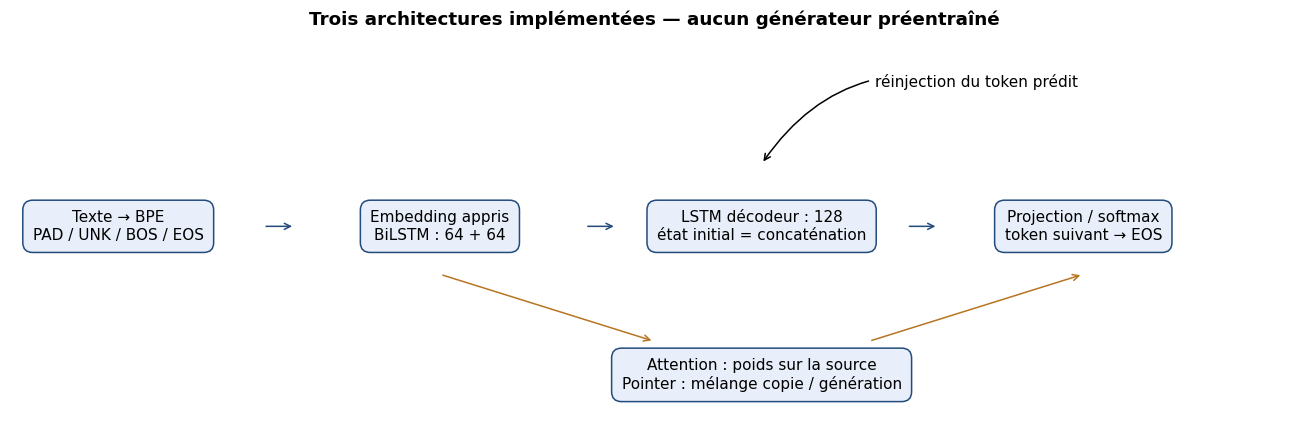

In [4]:
draw_architecture()

<a id="part-04"></a>
## 4. Implémentation depuis zéro

*From scratch requirement*

Les embeddings et tous les poids génératifs ont été initialisés aléatoirement et entraînés
sur ParaDetox. Charger un checkpoint de notre modèle ne transforme pas celui-ci en générateur
préentraîné externe. Aucun GPT, T5, BART, LLaMA ni API générative n’est utilisé.

RoBERTa (classification de toxicité) et MiniLM (embeddings sémantiques) sont uniquement des instruments
d’évaluation. Ils ne choisissent ni ne réécrivent les mots de la démonstration.
Le CPU local a été vérifié ; une reproduction GPU peut varier légèrement malgré les graines fixées.

In [5]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [6]:
seed_everything(SEED)

<a id="part-05"></a>
## 5. Jeu de données

*Dataset*

Le corpus public [s-nlp/paradetox](https://huggingface.co/datasets/s-nlp/paradetox), révision
`958b799`, fournit `en_toxic_comment → en_neutral_comment`. Le téléchargement est contrôlé par SHA-256.
Les statistiques ci-dessous sont calculées sur le fichier téléchargé. Le découpage sera reconstruit
dans la partie 6, puis comparé à l’empreinte de l’expérience initiale.

In [7]:
def download_dataset():
    url = 'https://huggingface.co/datasets/s-nlp/paradetox/resolve/958b799/train.tsv'
    expected = '6c305890c135b52b55ccf0587f69724ab118e27886ffcbfce468f6fe89c72ebc'
    path = ROOT / 'data/raw.tsv'
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists() or hashlib.sha256(path.read_bytes()).hexdigest() != expected:
        for attempt in range(3):
            try:
                request = urllib.request.Request(url, headers={'User-Agent': 'ParaDetox-academic-notebook'})
                with urllib.request.urlopen(request, timeout=90) as response:
                    content = response.read()
                if hashlib.sha256(content).hexdigest() != expected:
                    raise ValueError('Le contenu public ne correspond pas à la révision attendue.')
                path.write_bytes(content)
                break
            except Exception:
                if attempt == 2: raise
                time.sleep(2 ** attempt)
    return pd.read_csv(path, sep='\t')

In [8]:
raw=download_dataset()
print('Paires brutes :',len(raw))
display(raw[['en_toxic_comment','en_neutral_comment']].head(5))

Paires brutes : 19744


,en_toxic_comment,en_neutral_comment
0,he had steel balls too !,he was brave too!
1,"dude should have been taken to api , he would ...",It would have been good if he went to api. He ...
2,"im not gonna sell the fucking picture , i just...","I'm not gonna sell the picture, i just want to..."
3,the garbage that is being created by cnn and o...,the news that is being created by cnn and othe...
4,the reason they dont exist is because neither ...,The reason they don't exist is because neither...


<a id="part-06"></a>
## 6. Prétraitement des textes

*Text preprocessing*

Normalisation NFKC, espaces et minuscules : réduire les variantes sans supprimer la ponctuation
ni les négations. La casse des noms n’est donc pas préservée. Les paires vides et doublons sont retirés.
Pour éviter une fuite exacte, toute paire dont un texte source **ou cible** rejoint un autre après
suppression de ponctuation appartient à la même composante. Les composantes sont réparties environ
80/10/10, avec la graine 42. Cela ne prouve pas l’absence de quasi-doublons sémantiques.

`readable` est une normalisation **symétrique de métriques**, appliquée aux prédictions et références.
Elle ne corrige pas les sorties du générateur. Aucun tronquage des phrases ParaDetox à l’entraînement ;
la génération s’arrête à EOS ou à la limite configurée de **64 tokens générés** (y compris EOS si émis). Les évaluateurs ont leurs propres limites de longueur.

In [9]:
def normalize(text):
    # Same rule for split grouping and model inputs.
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(text))).strip().lower()

In [10]:
def readable(text):
    # Symmetric metric-only normalization of old tokenized punctuation.
    # Do NOT apply only to references or only to model outputs.
    text = normalize(text)
    text = re.sub(r"\s+([.,!?;:%])", r"\1", text)
    text = re.sub(r"\b(\w+)\s+'\s+(\w+)\b", r"\1'\2", text)
    text = re.sub(r"\s+n't\b", "n't", text)
    return text

In [11]:
def strict_split(raw):
    """Group connected source/target text to prevent cross-split exact overlap."""
    frame = raw[['en_toxic_comment', 'en_neutral_comment']].dropna().copy()
    frame.columns = ['source', 'target']
    for col in frame: frame[col] = frame[col].map(normalize)
    frame = frame[frame.source.ne('') & frame.target.ne('')].drop_duplicates()
    frame = frame.sort_values(['source', 'target']).reset_index(drop=True)
    parent = list(range(len(frame)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    seen = {}
    for i, row in enumerate(frame.itertuples(index=False)):
        for text in (row.source, row.target):
            key = re.sub(r'[^\w]', '', normalize(text))
            if key in seen: parent[find(i)] = find(seen[key])
            else: seen[key] = i
    groups = {}
    for i in range(len(frame)): groups.setdefault(find(i), []).append(i)
    components = list(groups.values())
    np.random.default_rng(42).shuffle(components)
    bins = {name: [] for name in ['train', 'validation', 'test']}
    targets = dict(zip(bins, [.8*len(frame), .1*len(frame), .1*len(frame)]))
    for component in sorted(components, key=len, reverse=True):
        name = max(bins, key=lambda n: (targets[n]-len(bins[n]))/targets[n])
        bins[name].extend(component)
    splits = {n: frame.iloc[ix].sort_values(['source', 'target']).reset_index(drop=True)
              for n, ix in bins.items()}
    keys = {n: {re.sub(r'[^\w]', '', text) for text in list(f.source)+list(f.target)}
            for n, f in splits.items()}
    assert not any(keys[a] & keys[b] for a, b in [('train','validation'),('train','test'),('validation','test')])
    signature = hashlib.sha256(''.join(n+f.to_csv(index=False) for n,f in splits.items()).encode()).hexdigest()
    print("Empreinte de la partition courante (non comparée à un ancien run) :", signature)
    for name, frame in splits.items(): frame.to_csv(ROOT/'data'/f'{name}.csv', index=False)
    return splits, signature

In [12]:
splits,DATA_SIGNATURE=strict_split(raw)
display(pd.DataFrame([{'partition':name,'paires':len(f),'sources':f.source.nunique()}
                      for name,f in splits.items()]))
print('Paires retenues :',sum(len(f) for f in splits.values()),'| Signature vérifiée :',DATA_SIGNATURE)
print('Normalisation :',normalize('  Do NOT delete June 14!  '))

Empreinte de la partition courante (non comparée à un ancien run) : 84ea545b313fcafb81c2636e0326fa3a337882639df83873266ca2781ec37cb4


,partition,paires,sources
0,train,15201,9541
1,validation,1901,1193
2,test,1901,1193


Paires retenues : 19003 | Signature vérifiée : 84ea545b313fcafb81c2636e0326fa3a337882639df83873266ca2781ec37cb4
Normalisation : do not delete june 14!


### Augmentation contrôlée du train (sans fuite de données)
Un faible nombre de paires **cible neutre → cible neutre** aide à préserver les phrases déjà correctes. Nous augmentons aussi légèrement la fréquence des exemples du **train** comportant nombres ou négations. Cela constitue une **hypothèse à valider**, et ne modifie ni validation ni test. La comparaison des architectures utilise le même ensemble d'entraînement augmenté.

⚠️ Cette augmentation peut aussi renforcer la copie des textes toxiques : son effet doit être vérifié par la validation.

In [13]:
def build_training_splits(original, identity_fraction=0.08, rare_fraction=0.25, seed=42):
    rng = np.random.default_rng(seed)
    train = original['train'].copy()
    targets = train.target.drop_duplicates().sort_values().tolist()
    picked = rng.choice(len(targets), size=int(identity_fraction*len(train)), replace=False)
    identity = pd.DataFrame({'source': [targets[i] for i in picked],
                             'target': [targets[i] for i in picked]})
    rare = train[train.source.str.contains(r"\d|\b(?:not|never|without|don't|can't|doesn't)\b",
                                          case=False, regex=True)]
    if len(rare):
        indices = rng.choice(len(rare), size=int(rare_fraction*len(rare)), replace=True)
        extras = rare.iloc[indices].copy()
    else:
        extras = rare.copy()
    augmented = pd.concat([train, identity, extras], ignore_index=True)
    assert len(augmented) >= len(train)
    for split in ['validation','test']:
        assert not set(augmented.source).intersection(set(original[split].source))
    print('Entraînement original :', len(train), '| Après augmentation :', len(augmented))
    print('Paires neutres→neutres ajoutées :',len(identity),'| rares rééchantillonnées :',len(extras))
    return {**original, 'train': augmented}
TRAINING_SPLITS = build_training_splits(splits)
AUGMENTATION_SIGNATURE = hashlib.sha256(
    (DATA_SIGNATURE + TRAINING_SPLITS['train'].to_csv(index=False)).encode()).hexdigest()

Entraînement original : 15201 | Après augmentation : 16823
Paires neutres→neutres ajoutées : 1216 | rares rééchantillonnées : 406


<a id="part-07"></a>
## 7. Représentation des tokens

*Word/token representation*

Nous entraînons un tokenizer **SentencePiece BPE de 2 000 sous-mots** uniquement sur la partition d'entraînement. Le modèle convertit chaque phrase en IDs, puis une couche `Embedding` transforme les IDs en vecteurs denses.

Les IDs spéciaux sont : `PAD=0`, `UNK=1`, `BOS=2`, `EOS=3`. Cette étape est déterministe à partir des données téléchargées ; aucun vocabulaire de validation ou de test n'est utilisé pendant son apprentissage.


In [14]:
def build_tokenizer(train, directory, vocab_size=2000):
    # Use unique TRAIN texts only. No validation/test vocabulary information.
    corpus = directory / "tokenizer_train.txt"
    texts = sorted(set(train.source) | set(train.target))
    corpus.write_text("\n".join(texts), encoding="utf-8")
    spm.SentencePieceTrainer.train(
        input=str(corpus), model_prefix=str(directory / "tokenizer"),
        vocab_size=vocab_size, model_type="bpe", character_coverage=1.0,
        pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
        shuffle_input_sentence=False, num_threads=1,
        hard_vocab_limit=False, minloglevel=2)
    return spm.SentencePieceProcessor(model_file=str(directory / "tokenizer.model"))

In [15]:
class TextPairs(Dataset):
    def __init__(self, frame, tokenizer):
        self.items = []
        for row in frame.itertuples(index=False):
            source = tokenizer.encode(row.source, out_type=int)
            target = tokenizer.encode(row.target, out_type=int)
            self.items.append((
                torch.tensor(source + [EOS], dtype=torch.long),
                torch.tensor([BOS] + target + [EOS], dtype=torch.long)))
    def __len__(self):
        return len(self.items)
    def __getitem__(self, index):
        return self.items[index]

In [16]:
def collate(items):
    source, target = zip(*items)
    lengths = torch.tensor([len(s) for s in source], dtype=torch.long)
    return (pad_sequence(source, batch_first=True, padding_value=PAD),
            lengths,
            pad_sequence(target, batch_first=True, padding_value=PAD))

In [17]:
def loader(frame, tokenizer, batch_size=32, shuffle=False):
    return DataLoader(TextPairs(frame, tokenizer), batch_size=batch_size,
                      shuffle=shuffle, collate_fn=collate, num_workers=0)

In [18]:
# Vocabulaire appris uniquement sur TRAIN : pas de fuite par validation/test.
TOKENIZER_DIR = ROOT / 'tokenizer'
TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)
TOKENIZER_FILE = TOKENIZER_DIR / 'tokenizer.model'
VOCAB_REQUESTED = 2000  # expérience V3 (vocabulaire élargi) ; toute modification exige réentraînement.
TOKEN_META = TOKENIZER_DIR / 'train_signature.json'
expected_tokenizer = {'data_signature': DATA_SIGNATURE, 'requested_vocab': VOCAB_REQUESTED}
if TOKENIZER_FILE.exists():
    if not TOKEN_META.exists() or json.loads(TOKEN_META.read_text()) != expected_tokenizer:
        raise RuntimeError('Tokenizer ancien/incompatible : utiliser un nouveau ROOT ou effacer tokenizer/ et runs/.')
    tokenizer = spm.SentencePieceProcessor(model_file=str(TOKENIZER_FILE))
else:
    tokenizer = build_tokenizer(splits['train'], TOKENIZER_DIR, vocab_size=VOCAB_REQUESTED)
    TOKEN_META.write_text(json.dumps(expected_tokenizer))
assert [tokenizer.pad_id(), tokenizer.unk_id(), tokenizer.bos_id(), tokenizer.eos_id()] == [PAD, UNK, BOS, EOS]

### Ressource auxiliaire de fluidité, apprise exclusivement sur TRAIN
Le reranking utilise la fréquence des mots et bigrammes de phrases cibles (neutres) du train. Il pénalise faiblement les **nouveaux mots déformés**, sans insérer de réponses prédéfinies ni employer un modèle génératif préentraîné.

In [19]:
def lexical_tokens(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+(?:[.,]\d+)*", normalize(text))

def build_target_language_stats(train):
    words, pairs, toxic_source, neutral_target = Counter(), Counter(), Counter(), Counter()
    for row in train.itertuples(index=False):
        src, tgt = lexical_tokens(row.source), lexical_tokens(row.target)
        words.update(tgt); pairs.update(zip(tgt, tgt[1:]))
        toxic_source.update(src); neutral_target.update(tgt)
    changed = {w for w, n in toxic_source.items()
               if n >= 4 and n >= 3*max(1,neutral_target[w]) and n-neutral_target[w]>=4}
    return {'words': words, 'bigrams': pairs, 'source_biased': changed}

TARGET_LM = build_target_language_stats(splits['train'])
print('Vocabulaire cible du train :',len(TARGET_LM['words']))

Vocabulaire cible du train : 9996


In [20]:
sentence = normalize('Please send me the report.')
display(pd.DataFrame({'sous-mot': tokenizer.encode(sentence, out_type=str),
                      'id': tokenizer.encode(sentence)}))
source, lengths, target = next(iter(loader(splits['train'].head(3), tokenizer, 3)))
embedding_demo = nn.Embedding(tokenizer.get_piece_size(), 64, padding_idx=PAD)
print('Source', tuple(source.shape), '| longueurs', lengths.tolist(), '| cible', tuple(target.shape))
print('Embedding', tuple(embedding_demo(source).shape), '| vocabulaire', tokenizer.get_piece_size())

,sous-mot,id
0,▁please,576
1,▁send,906
2,▁me,96
3,▁the,13
4,▁report,1655
5,.,1951


Source (3, 24) | longueurs [21, 24, 18] | cible (3, 24)
Embedding (3, 24, 64) | vocabulaire 2000


<a id="part-08"></a>
## 8. Encodeur

*Encoder*

Le BiLSTM parcourt la source dans les deux sens : chaque état combine contexte gauche et droit.
Dans les expériences principales, chaque direction utilise **96 dimensions**, concaténées en **192**. Pour une direction :
$$i_t,f_t,o_t=\sigma(W[E(x_t);h_{t-1}]+b),\quad g_t=\tanh(W_g[E(x_t);h_{t-1}]+b_g),$$
$$c_t=f_t\odot c_{t-1}+i_t\odot g_t,\qquad h_t=o_t\odot\tanh(c_t).$$
Les quatre portes ont des paramètres distincts, regroupés dans `nn.LSTM`.
On concatène les états finaux cachés **et cellules** pour initialiser le décodeur.
`pack_padded_sequence` empêche le PAD d’altérer les états finaux.

In [21]:
class Encoder(nn.Module):
    """Bidirectional encoder; concatenate the two directions into decoder states."""
    def __init__(self, embedding, hidden_size, dropout):
        super().__init__()
        assert hidden_size % 2 == 0
        self.embedding = embedding
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.LSTM(embedding.embedding_dim, hidden_size // 2,
                           batch_first=True, bidirectional=True)
    def forward(self, source, lengths):
        packed = pack_padded_sequence(
            self.dropout(self.embedding(source)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        outputs, (h, c) = self.rnn(packed)
        outputs, _ = pad_packed_sequence(
            outputs, batch_first=True, total_length=source.shape[1])
        h = torch.cat([h[0], h[1]], dim=-1).unsqueeze(0)
        c = torch.cat([c[0], c[1]], dim=-1).unsqueeze(0)
        return outputs, (h, c)

In [22]:
encoder_demo=Encoder(embedding_demo,128,0.).eval()
with torch.inference_mode(): encoder_outputs,initial_state=encoder_demo(source,lengths)
print('États source [B,S,H] :',tuple(encoder_outputs.shape))
print('États initiaux h et c :',[tuple(t.shape) for t in initial_state])

États source [B,S,H] : (3, 24, 128)
États initiaux h et c : [(1, 3, 128), (1, 3, 128)]


<a id="part-09"></a>
## 9. Décodeur

*Decoder*

À l’étape $t$, le décodeur reçoit le token précédent et l’état $(h,c)$ :
$$s_t=\mathrm{LSTM}(E[y_{t-1}],s_{t-1}),\qquad p_{vocab}=\mathrm{softmax}(Wz_t+b).$$
Pour la baseline, $z_t=s_t$ ; avec attention, $z_t=[s_t;c_t]$.
La distribution porte sur le vocabulaire BPE. L’attention intervient **dans la projection de sortie**,
sans *input feeding*. Le bloc pointer ci-dessous sera détaillé en partie 11.
Le modèle complet partage l’embedding entre encodeur et décodeur.

In [23]:
class Decoder(nn.Module):
    def __init__(self, embedding, hidden_size, dropout, variant):
        super().__init__()
        assert variant in ("baseline", "attention", "pointer")
        self.variant = variant
        self.embedding = embedding
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.LSTM(embedding.embedding_dim, hidden_size, batch_first=True)
        self.query = nn.Linear(hidden_size, hidden_size, bias=False) if variant != "baseline" else None
        features = hidden_size if variant == "baseline" else hidden_size * 2
        self.output = nn.Linear(features, embedding.num_embeddings)
        self.gate = (nn.Linear(features + embedding.embedding_dim, 1)
                     if variant == "pointer" else None)

    def forward(self, previous, state, encoder_outputs, source):
        # previous: [batch, target_steps]. Whole target is available only in training.
        embeddings = self.dropout(self.embedding(previous))
        hidden, state = self.rnn(embeddings, state)
        attention = None
        if self.variant == "baseline":
            features = hidden
        else:
            attention, context = masked_attention(self.query(hidden), encoder_outputs, source)
            features = torch.cat([hidden, context], dim=-1)
        logits = self.output(self.dropout(features))
        log_probs = torch.log_softmax(logits, dim=-1)
        gate = None
        if self.variant == "pointer":
            # Mix vocabulary generation with copying source subword IDs.
            # Repeated source IDs accumulate their probability via scatter_add.
            gate = torch.sigmoid(self.gate(torch.cat([features, embeddings], dim=-1)))
            probs = gate * log_probs.exp()
            copy_mass = (1.0 - gate) * attention
            indices = source.unsqueeze(1).expand(-1, previous.size(1), -1)
            probs = probs.scatter_add(2, indices, copy_mass)
            log_probs = probs.clamp_min(1e-9).log()
        return log_probs, state, attention, gate

In [24]:
class RewriteModel(nn.Module):
    def __init__(self, vocab_size, config, variant):
        super().__init__()
        self.variant = variant
        embedding = nn.Embedding(vocab_size, config['embedding_dim'], padding_idx=PAD)
        self.encoder = Encoder(embedding, config['hidden_dim'], config['dropout'])
        self.decoder = Decoder(embedding, config['hidden_dim'], config['dropout'], variant)

    def forward(self, source, lengths, target_input, teacher_forcing_ratio=1.0):
        outputs, state = self.encoder(source, lengths)
        if teacher_forcing_ratio >= 1.0 or not self.training:
            return self.decoder(target_input, state, outputs, source)[0]
        # Sampling token par token (uniquement pour l'expérience prolongée).
        previous = target_input[:, :1]
        steps = []
        for t in range(target_input.size(1)):
            logp, state, _, _ = self.decoder(previous, state, outputs, source)
            steps.append(logp)
            if t + 1 < target_input.size(1):
                predicted = logp[:, -1].detach().argmax(-1)
                gold = target_input[:, t+1]
                use_gold = torch.rand(gold.shape, device=gold.device) < teacher_forcing_ratio
                previous = torch.where(use_gold | gold.eq(PAD), gold, predicted).unsqueeze(1)
        return torch.cat(steps, dim=1)

In [25]:
decoder_demo=Decoder(embedding_demo,128,0.,'baseline').eval()
with torch.inference_mode():
    logp,_,_,_=decoder_demo(target[:,:1],initial_state,encoder_outputs,source)
print('Distribution [B,1,V] :',tuple(logp.shape),'| somme :',logp.exp().sum(-1).tolist())

Distribution [B,1,V] : (3, 1, 2000) | somme : [[1.0000001192092896], [0.9999998807907104], [0.9999998211860657]]


<a id="part-10"></a>
## 10. Teacher forcing

*Teacher forcing*

Teacher forcing initial à 100 % : la cible décalée `target[:, :-1]` est fournie au décodeur,
qui prédit `target[:, 1:]`. Pendant l’inférence, aucune cible n’est accessible : les prédictions sont
réinjectées. Cette différence crée un biais d’exposition ; la V3 expérimente un **scheduled sampling** progressif sur l'Attention prolongée uniquement.
$$\mathcal{L}=-\frac{1}{N_{\neg PAD}}\sum_{b,t:y_{b,t}\ne PAD}\log p_\theta(y_{b,t}\mid y_{b,<t},x_b).$$
Le décodeur renvoie des log-probabilités : NLLLoss équivaut ici à l’entropie croisée après normalisation.

**Protocole effectivement implémenté :** les trois entraînements initiaux utilisent un taux de teacher forcing de **1,0**. Pour l’expérience **Attention prolongée**, le code active un *scheduled sampling* token par token : le taux cible décroît progressivement de **1,0 à 0,85 après l’époque 12**, selon le nombre d’époques effectivement réalisées. L’augmentation du budget d’entraînement et le changement de stratégie intervenant ensemble, cette expérience **n’isole pas l’effet causal** du scheduled sampling ; elle reste exploratoire.

In [26]:
def token_loss(log_probs, gold):
    return nn.functional.nll_loss(
        log_probs.reshape(-1, log_probs.size(-1)), gold.reshape(-1),
        ignore_index=PAD, reduction="sum")

In [27]:
print('Entrée teacher forcing :',target[0,:8].tolist())
print('Entrée décodeur décalée :',target[0,:-1][:7].tolist())
print('Tokens à prédire :',target[0,1:][:7].tolist())
print('NLL première étape (réseau aléatoire de démonstration) :',float(token_loss(logp,target[:,1:2])/target[:,1:2].ne(PAD).sum()))

Entrée teacher forcing : [2, 53, 1953, 1935, 979, 3, 0, 0]
Entrée décodeur décalée : [2, 53, 1953, 1935, 979, 3, 0]
Tokens à prédire : [53, 1953, 1935, 979, 3, 0, 0]
NLL première étape (réseau aléatoire de démonstration) : 7.56640100479126


<a id="part-11"></a>
## 11. Mécanisme d’attention

*Attention mechanism*

### Attention et mécanisme de copie
La représentation finale fixe peut oublier des détails. L’attention calcule
$$e_{t,i}=q(s_t)^\top H_i/\sqrt{d},\quad\alpha_{t,i}=\mathrm{softmax}_i(e_{t,i}),\quad c_t=\sum_i\alpha_{t,i}H_i.$$
Les positions PAD reçoivent $-\infty$ avant softmax. Le contexte dépend donc de l’étape de sortie.

Le pointer apprend $g_t=\sigma(w^\top[s_t;c_t;E(y_{t-1})]+b)$ puis
$$p(w)=g_t p_{vocab}(w)+(1-g_t)\sum_{i:x_i=w}\alpha_{t,i}.$$
`scatter_add` additionne la masse des occurrences du même sous-mot. Une petite porte favorise la copie,
mais la copie peut aussi conserver une insulte. Ce mécanisme ne reconnaît pas explicitement les entités
et ne peut recopier un caractère déjà transformé en UNK.

In [28]:
def masked_attention(query, encoder_outputs, source):
    """query [B,T,H], encoder [B,S,H], source [B,S]; return weights and context."""
    scores = torch.bmm(query, encoder_outputs.transpose(1, 2)) / math.sqrt(query.size(-1))
    scores = scores.masked_fill(~source.ne(PAD).unsqueeze(1), float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights, torch.bmm(weights, encoder_outputs)

In [29]:
pointer_demo=RewriteModel(tokenizer.get_piece_size(),{'embedding_dim':64,'hidden_dim':128,'dropout':0.},'pointer').eval()
with torch.inference_mode():
    encoded,state=pointer_demo.encoder(source,lengths)
    probabilities,_,weights,gate=pointer_demo.decoder(target[:,:2],state,encoded,source)
assert torch.allclose(weights.sum(-1),torch.ones_like(weights.sum(-1)),atol=1e-5)
assert (weights.masked_select(~source.ne(PAD).unsqueeze(1).expand_as(weights))==0).all()
print('Attention :',tuple(weights.shape),'| porte génération :',gate[:,:,0].tolist())
print('Somme de la distribution pointer :',probabilities.exp().sum(-1).tolist())
print('Démonstration de calcul aléatoire, pas une mesure de qualité linguistique.')

Attention : (3, 2, 24) | porte génération : [[0.5023174285888672, 0.43494701385498047], [0.49506130814552307, 0.5777710676193237], [0.4907890558242798, 0.4825392961502075]]
Somme de la distribution pointer : [[0.9999998807907104, 0.9999998807907104], [0.9999999403953552, 0.9999998807907104], [1.0000001192092896, 1.0]]
Démonstration de calcul aléatoire, pas une mesure de qualité linguistique.


<a id="part-12"></a>
## 12. Entraînement

*Training*

Nous comparons **trois architectures entraînées de zéro**, avec AdamW, learning rate 0,002, batch 64, dropout 0,25, embeddings 96, hidden 192, weight decay 0,0001 et gradient clipping à 1. Le budget commun est de **14 époques**, avec early stopping si la NLL validation cesse de progresser.

Une expérience supplémentaire prolonge l'attention jusqu'à 25 époques maximum. Elle est indiquée séparément, car ce n'est plus une comparaison à budget égal.

Les checkpoints `best` minimisent la perte de validation ; `last` permet de reprendre un entraînement interrompu dans le même runtime. Aucune ancienne mesure n'est utilisée pour sélectionner un modèle nouvellement entraîné.


In [30]:
def epoch_pass(model, batches, device, optimizer=None, teacher_forcing_ratio=1.0):
    model.train(optimizer is not None)
    total_loss, tokens = 0., 0
    for source, lengths, target in batches:
        source, target = source.to(device), target.to(device)
        with torch.set_grad_enabled(optimizer is not None):
            ratio = teacher_forcing_ratio if optimizer is not None else 1.0
            log_probs = model(source, lengths, target[:, :-1], ratio)
            count = target[:, 1:].ne(PAD).sum()
            loss_sum = token_loss(log_probs, target[:, 1:])
            if not torch.isfinite(loss_sum):
                raise RuntimeError('Nonfinite token loss')
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
                (loss_sum / count.clamp_min(1)).backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
        total_loss += loss_sum.detach().item()
        tokens += count.item()
    return total_loss / max(1,tokens)

In [31]:
def atomic_torch_save(payload, path):
    temp = path.with_suffix(".tmp")
    torch.save(payload, temp)
    os.replace(temp, path)

In [32]:
def init_training(variant, seed, config, tokenizer, directory, device, signature):
    """Créer ou restaurer un run et son optimiseur, sans mélanger deux expériences."""
    name = f"{variant}_seed{seed}"
    seed_everything(seed)
    model = RewriteModel(tokenizer.get_piece_size(), config, variant).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['learning_rate'],
                                   weight_decay=config['weight_decay'])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=.5, patience=1)
    last = directory / f'{name}_last.pt'
    history, best, bad, start = [], float('inf'), 0, 1
    token_hash = hashlib.sha256(tokenizer.serialized_model_proto()).hexdigest()
    if last.exists():
        saved = torch.load(last, map_location=device, weights_only=False)
        compatible = (saved['config']==config and saved['data_signature']==signature
                      and saved['tokenizer_hash']==token_hash and saved['variant']==variant
                      and saved['seed']==seed and saved.get('implementation_version')==IMPLEMENTATION_VERSION)
        if not compatible: raise ValueError('Checkpoint incompatible avec ce run.')
        model.load_state_dict(saved['state_dict'])
        optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler'])
        history, best, bad = saved['history'], saved['best'], saved['bad']
        start = saved['epoch'] + 1
        print(f'Reprise de {name}, époque {start}')
    return model, optimizer, scheduler, history, best, bad, start, token_hash


In [33]:
def save_training_epoch(variant, seed, config, model, optimizer, scheduler,
                        epoch, best, bad, history, directory, signature, token_hash, improved):
    """Enregistrer le dernier état et le meilleur checkpoint validation."""
    name = f'{variant}_seed{seed}'
    payload = dict(variant=variant, seed=seed, config=config,
                   vocab_size=model.encoder.embedding.num_embeddings,
                   state_dict=model.state_dict(), optimizer=optimizer.state_dict(),
                   scheduler=scheduler.state_dict(), epoch=epoch, best=best, bad=bad,
                   history=history, data_signature=signature, tokenizer_hash=token_hash,
                   implementation_version=IMPLEMENTATION_VERSION,
                   parameters=sum(p.numel() for p in model.parameters()))
    if improved:
        atomic_torch_save(payload, directory / f'{name}_best.pt')
    atomic_torch_save(payload, directory / f'{name}_last.pt')
    pd.DataFrame(history).to_csv(directory / f'{name}_history.csv', index=False)

In [34]:
def train_run(variant, seed, config, tokenizer, splits, directory, device, signature):
    """Boucle d'entraînement, validation et early stopping."""
    model, optimizer, scheduler, history, best, bad, start, token_hash = init_training(
        variant, seed, config, tokenizer, directory, device, signature)
    train_batches = loader(splits['train'], tokenizer, config['batch_size'], True)
    train_eval = loader(splits['train'], tokenizer, config['batch_size'])
    validation = loader(splits['validation'], tokenizer, config['batch_size'])
    print(variant, '| paramètres', sum(p.numel() for p in model.parameters()))
    if bad < config['patience']:
        for epoch in range(start, config['epochs']+1):
            seed_everything(seed + epoch)
            begin = time.perf_counter()
            ratio_start = config.get('teacher_forcing_ratio', 1.0)
            ratio_end = config.get('teacher_forcing_end', ratio_start)
            anneal = min(1., max(0., (epoch - 12) / max(1, config['epochs'] - 12)))
            ratio = ratio_start + (ratio_end - ratio_start) * anneal
            train_nll = epoch_pass(model, train_batches, device, optimizer, ratio)
            val_nll = epoch_pass(model, validation, device)
            train_eval_nll = epoch_pass(model, train_eval, device)
            if not math.isfinite(train_nll + val_nll): raise RuntimeError('Loss non finie.')
            improved = val_nll < best - config['min_delta']
            best, bad = (val_nll, 0) if improved else (best, bad + 1)
            scheduler.step(val_nll)
            history.append({'epoch':epoch, 'train_nll':train_nll, 'val_nll':val_nll,
                            'train_eval_nll':train_eval_nll, 'seconds':time.perf_counter()-begin,
                            'learning_rate':optimizer.param_groups[0]['lr'], 'teacher_forcing': ratio})
            save_training_epoch(variant, seed, config, model, optimizer, scheduler,
                                epoch, best, bad, history, directory, signature, token_hash, improved)
            print(f'{variant} {epoch:02d} | train {train_nll:.3f} | val {val_nll:.3f}', flush=True)
            if bad >= config['patience']:
                print('Arrêt anticipé ; meilleur checkpoint conservé.')
                break
    del model, optimizer
    if device.type=='cuda': torch.cuda.empty_cache()
    return pd.DataFrame(history)

In [35]:
def load_run(path, tokenizer, device):
    # Only load checkpoints created by this notebook.
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    assert hashlib.sha256(tokenizer.serialized_model_proto()).hexdigest() == checkpoint["tokenizer_hash"]
    model = RewriteModel(checkpoint["vocab_size"], checkpoint["config"],
                         checkpoint["variant"]).to(device)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint

In [36]:
def experiment_config():
    """Hyperparamètres V3 : tous les runs nécessitent un entraînement depuis zéro."""
    return dict(embedding_dim=96, hidden_dim=192, dropout=.25,
                batch_size=64, epochs=14, patience=4, min_delta=.005,
                learning_rate=.002, weight_decay=.0001,
                teacher_forcing_ratio=1., tokenizer_vocab_size=2000,
                max_generation=64)

def initialize_runs():
    config = experiment_config()
    original = ROOT / 'runs/original'
    extended = ROOT / 'runs/attention_extended'
    original.mkdir(parents=True, exist_ok=True)
    extended.mkdir(parents=True, exist_ok=True)
    for variant in ['baseline','attention','pointer']:
        train_run(variant, SEED, config, tokenizer, TRAINING_SPLITS, original, DEVICE, AUGMENTATION_SIGNATURE)
    if TRAIN_EXTENDED_ATTENTION:
        ext_config = dict(config, epochs=25, patience=5, teacher_forcing_end=.85)
        for kind in ['last','best']:
            target_file = extended / f'attention_seed{SEED}_{kind}.pt'
            if not target_file.exists():
                cp = torch.load(original / f'attention_seed{SEED}_{kind}.pt',
                                map_location='cpu', weights_only=False)
                cp['config'] = ext_config.copy()
                atomic_torch_save(cp, target_file)
        train_run('attention', SEED, ext_config, tokenizer, TRAINING_SPLITS,
                  extended, DEVICE, AUGMENTATION_SIGNATURE)
    paths={name: original / f'{name}_seed{SEED}_best.pt'
           for name in ['baseline','attention','pointer']}
    if TRAIN_EXTENDED_ATTENTION:
        paths['extended'] = extended / f'attention_seed{SEED}_best.pt'
    models, checkpoints = {}, {}
    for name,path in paths.items():
        models[name], checkpoints[name] = load_run(path, tokenizer, DEVICE)
    return config, paths, models, checkpoints

In [37]:
config, model_paths, models, checkpoints = initialize_runs()
display(pd.DataFrame([config]).T.rename(columns={0:'configuration'}))
display(pd.DataFrame([{'modèle':name,'paramètres':cp['parameters'],
                       'époque sélectionnée':cp['epoch']} for name,cp in checkpoints.items()]))
print('Poids entraînés ou repris dans ce runtime. Aucun checkpoint binaire dans le notebook.')


baseline | paramètres 949712
baseline 01 | train 5.616 | val 4.981
baseline 02 | train 4.739 | val 4.465
baseline 03 | train 4.296 | val 4.193
baseline 04 | train 3.996 | val 4.017
baseline 05 | train 3.779 | val 3.893
baseline 06 | train 3.608 | val 3.804
baseline 07 | train 3.478 | val 3.733
baseline 08 | train 3.362 | val 3.681
baseline 09 | train 3.271 | val 3.636
baseline 10 | train 3.188 | val 3.608
baseline 11 | train 3.114 | val 3.577
baseline 12 | train 3.052 | val 3.550
baseline 13 | train 2.996 | val 3.526
baseline 14 | train 2.943 | val 3.507
attention | paramètres 1370576
attention 01 | train 5.203 | val 3.776
attention 02 | train 2.860 | val 1.997
attention 03 | train 1.799 | val 1.696
attention 04 | train 1.509 | val 1.616
attention 05 | train 1.372 | val 1.586
attention 06 | train 1.279 | val 1.554
attention 07 | train 1.211 | val 1.545
attention 08 | train 1.162 | val 1.545
attention 09 | train 1.116 | val 1.523
attention 10 | train 1.076 | val 1.534
attention 11 | tra

,configuration
embedding_dim,96.0000
hidden_dim,192.0000
dropout,0.2500
batch_size,64.0000
epochs,14.0000
patience,4.0000
min_delta,0.0050
learning_rate,0.0020
weight_decay,0.0001
teacher_forcing_ratio,1.0000


,modèle,paramètres,époque sélectionnée
0,baseline,949712,14
1,attention,1370576,14
2,pointer,1371057,7
3,extended,1370576,25


Poids entraînés ou repris dans ce runtime. Aucun checkpoint binaire dans le notebook.


In [38]:
def learning_curves(paths):
    fig, axes = plt.subplots(2,2,figsize=(12,7),sharey=False)
    for (name,path), ax in zip(paths.items(),axes.flat):
        history_path = path.parent/f'{"attention" if name=="extended" else name}_seed42_history.csv'
        history = pd.read_csv(history_path) if history_path.exists() else pd.DataFrame(checkpoints[name]['history'])
        ax.plot(history.epoch,history.train_nll,label='Train, dropout actif',alpha=.65)
        ax.plot(history.epoch,history.train_eval_nll,label='Train, mode évaluation')
        ax.plot(history.epoch,history.val_nll,label='Validation',linewidth=2)
        ax.axvline(checkpoints[name]['epoch'],color='black',ls=':',label='Meilleur checkpoint')
        ax.set(title=name,xlabel='Époque',ylabel='NLL / token'); ax.grid(alpha=.2)
    axes[0,0].legend(fontsize=8)
    fig.suptitle('Historique réel des checkpoints chargés — une seule graine (42)')
    plt.tight_layout(); plt.show()

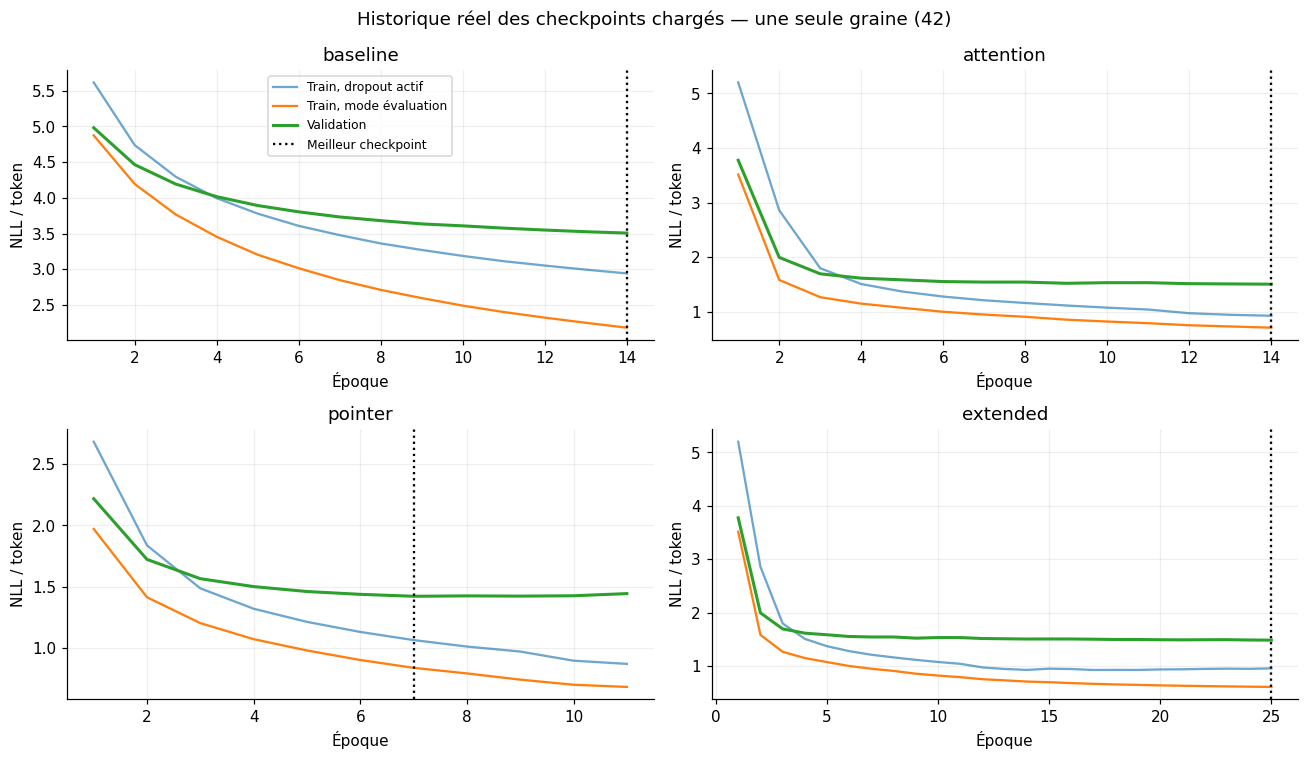

In [39]:
learning_curves(model_paths)

**Lecture des courbes.** Comparer train et validation en mode évaluation, car le dropout augmente
la difficulté du train d’optimisation. Un écart indique un risque de généralisation ; il ne prouve
pas à lui seul le surapprentissage. Les NLL ne mesurent pas la grammaticalité des phrases générées.

<a id="part-13"></a>
## 13. Génération et inférence

*Generation / inference*

La génération commence par BOS et réinjecte le token prédit. PAD et BOS sont interdits comme
sorties. EOS termine la séquence ; la limite de génération configurée est de **64 tokens**, et l’atteinte de cette limite est signalée.
La fonction ci-dessous traite des entrées seules, sans références et sans règles de réécriture cachées.

In [40]:
@torch.inference_mode()
def generate(model, texts, tokenizer, device, max_steps, batch_size=32):
    all_outputs = []
    model.eval()
    for begin in range(0, len(texts), batch_size):
        batch = texts[begin:begin+batch_size]
        seqs = [torch.tensor(tokenizer.encode(normalize(t)) + [EOS], dtype=torch.long) for t in batch]
        lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)
        source = pad_sequence(seqs, batch_first=True, padding_value=PAD).to(device)
        enc_outputs, state = model.encoder(source, lengths)
        token = torch.full((len(batch), 1), BOS, dtype=torch.long, device=device)
        done = torch.zeros(len(batch), dtype=torch.bool, device=device)
        pieces = [[] for _ in batch]
        for _ in range(max_steps):
            log_probs, state, _, _ = model.decoder(token, state, enc_outputs, source)
            scores = log_probs[:, 0, :].clone()
            scores[:, PAD] = float("-inf")
            scores[:, BOS] = float("-inf")
            next_token = scores.argmax(dim=-1)
            for i, value in enumerate(next_token.tolist()):
                if not done[i].item() and value != EOS:
                    pieces[i].append(value)
            done |= next_token.eq(EOS)
            token = torch.where(done, torch.full_like(next_token, EOS), next_token).unsqueeze(1)
            if done.all():
                break
        for i, ids in enumerate(pieces):
            all_outputs.append({"output": tokenizer.decode(ids),
                                "hit_length_limit": not done[i].item(),
                                "unk_count": ids.count(UNK)})
    return all_outputs

In [41]:
for name in ['baseline','attention','pointer']:
    output=generate(models[name],['Please send me the report.'],tokenizer,DEVICE,48)[0]
    print(name,':',output)

baseline : {'output': 'please give me the same.', 'hit_length_limit': False, 'unk_count': 0}
attention : {'output': 'please send me the report.', 'hit_length_limit': False, 'unk_count': 0}
pointer : {'output': 'please send me the report.', 'hit_length_limit': False, 'unk_count': 0}


<a id="part-14"></a>
## 14. Stratégies de décodage

*Decoding strategy*

En **greedy**, le décodeur sélectionne le token le plus probable à chaque étape. En **beam search**, il conserve quatre hypothèses et compare leurs probabilités normalisées par la longueur.

$$\mathrm{score}(y)=\frac{\sum_t \log p(y_t\mid y_{<t},x)}{((5+|y|)/6)^{0,6}}.$$

Nous comparons greedy, beam4, beam4 avec interdiction des trigrammes répétés et beam4 sans pénalité de longueur. Le candidat final est choisi **sur la validation**, avant l'examen du test.

Une piste exploratoire supplémentaire pénalise les changements de chiffres et de nombre de négations. Cette heuristique ne garantit pas le respect des relations logiques.


In [42]:
@torch.inference_mode()
def beam_generate(model,texts,tokenizer,device,max_steps,width=4,alpha=.6,no_repeat=0):
    """Length-normalized beam; optional ngram constraint is an explicit ablation."""
    result=[]; model.eval()
    for text in texts:
        source=torch.tensor([tokenizer.encode(normalize(text))+[EOS]],device=device)
        enc,state=model.encoder(source,torch.tensor([source.size(1)]))
        beams=[([],0.,state,False)]
        for _ in range(max_steps):
            candidates=[]
            for ids,score,st,done in beams:
                if done: candidates.append((ids,score,st,done)); continue
                previous=ids[-1] if ids else BOS
                lp,new_state,_,_=model.decoder(torch.tensor([[previous]],device=device),st,enc,source)
                lp=lp[0,0].clone(); lp[PAD]=lp[BOS]=-float('inf')
                if no_repeat and len(ids)>=no_repeat-1:
                    prefix=ids[-(no_repeat-1):] if no_repeat>1 else []
                    for i in range(len(ids)-no_repeat+1):
                        if ids[i:i+no_repeat-1]==prefix: lp[ids[i+no_repeat-1]]=-float('inf')
                values,indices=lp.topk(min(width,len(lp)))
                for value,idx in zip(values.tolist(),indices.tolist()):
                    candidates.append((ids+[idx],score+value,new_state,idx==EOS))
            def rank(b): return b[1]/(((5+len(b[0]))/6)**alpha)
            beams=sorted(candidates,key=rank,reverse=True)[:width]
            if all(b[3] for b in beams): break
        ids,score,_,done=max(beams,key=rank)
        result.append({'output':tokenizer.decode([i for i in ids if i!=EOS]),'hit_length_limit':not done,'unk_count':ids.count(UNK)})
    return result

In [43]:
def numeric_sequence(text):
    """Séquence des valeurs (ne traite pas les unités ou le rôle logique)."""
    return tuple(re.sub(r'\s+', '', s) for s in re.findall(
        r'(?<!\w)[$€£]?\s*\d+(?:[.,]\d+)*(?!\w)', readable(text)))

def negation_sequence(text):
    return tuple(re.findall(
        r"\b(?:not|never|no|without|cannot|can't|don't|doesn't|didn't|won't|shouldn't|isn't|aren't)\b",
        readable(text)))

def name_sequence(text):
    """Indices lexicaux : noms propres avec majuscule, en excluant le début de phrase."""
    return tuple(w.lower() for w in re.findall(r'(?<=\s)[A-Z][a-z]{2,}\b', text))

def factual_cost(source, candidate):
    src, out = numeric_sequence(source), numeric_sequence(candidate)
    missing = sum((Counter(src)-Counter(out)).values())
    added = sum((Counter(out)-Counter(src)).values())
    order_changed = src != out and Counter(src) == Counter(out)
    names_lost = sum((Counter(name_sequence(source))-Counter(lexical_tokens(candidate))).values())
    neg_changed = len(negation_sequence(source)) != len(negation_sequence(candidate))
    src_len, out_len = len(lexical_tokens(source)),len(lexical_tokens(candidate))
    short = max(0., .75 - out_len/max(1,src_len)) if src_len>=7 else 0.
    return (7.*(missing+added) + 4.*order_changed + 4.*names_lost
            + 1.0*neg_changed + 7.*short)

In [44]:
@torch.inference_mode()
def beam_rescore(model,texts,tokenizer,device,max_steps,width=6,alpha=.6,no_repeat=3,fact_penalty=1.0):
    """N-best reranking: decoded candidates are scored for simple factual loss."""
    result=[]; model.eval()
    for text in texts:
        source=torch.tensor([tokenizer.encode(normalize(text))+[EOS]],device=device)
        enc,state=model.encoder(source,torch.tensor([source.size(1)]))
        beams=[([],0.,state,False)]
        for _ in range(max_steps):
            candidates=[]
            for ids,score,st,done in beams:
                if done: candidates.append((ids,score,st,done)); continue
                previous=ids[-1] if ids else BOS
                lp,new_state,_,_=model.decoder(torch.tensor([[previous]],device=device),st,enc,source)
                lp=lp[0,0].clone(); lp[PAD]=lp[BOS]=-float('inf')
                if no_repeat and len(ids)>=no_repeat-1:
                    prefix=ids[-(no_repeat-1):] if no_repeat>1 else []
                    for i in range(len(ids)-no_repeat+1):
                        if ids[i:i+no_repeat-1]==prefix: lp[ids[i+no_repeat-1]]=-float('inf')
                values,indices=lp.topk(min(width,len(lp)))
                for value,idx in zip(values.tolist(),indices.tolist()):
                    candidates.append((ids+[idx],score+value,new_state,idx==EOS))
            def rank(b): return b[1]/(((5+len(b[0]))/6)**alpha)
            beams=sorted(candidates,key=rank,reverse=True)[:width]
            if all(b[3] for b in beams): break
        def final_rank(b):
            decoded=tokenizer.decode([i for i in b[0] if i!=EOS])
            return rank(b)-fact_penalty*factual_cost(text,decoded)
        ids,score,_,done=max(beams,key=final_rank)
        result.append({'output':tokenizer.decode([i for i in ids if i!=EOS]),
                       'hit_length_limit':not done,'unk_count':ids.count(UNK)})
    return result

### Sélection renforcée des sorties, sans réponses codées en dur
La V3 génère plusieurs candidats avec le réseau entraîné. Elle combine leur probabilité avec des **indices** de fluidité issus du train, de longueur, de copie inutile et de préservation des faits (chiffres/noms). Si aucune génération n'est fiable, une **alerte de révision** est conservée : le système ne prétend pas avoir réparé la phrase.

In [45]:
def candidate_penalty(source, candidate, hit_limit=False, unk_count=0):
    words = lexical_tokens(candidate)
    source_words = set(lexical_tokens(source))
    if not words: return 100.
    unseen = sum(w not in TARGET_LM['words'] and w not in source_words for w in words)
    bad_bigrams = sum((a,b) not in TARGET_LM['bigrams']
                      for a,b in zip(words,words[1:]))
    copied_bias = sum(w in TARGET_LM['source_biased'] for w in words)
    length_ratio = len(words)/max(1,len(lexical_tokens(source)))
    return (factual_cost(source,candidate) + 1.8*unseen
            + .12*bad_bigrams + .75*copied_bias
            + 4.0*max(0., .70-length_ratio) + 2.0*hit_limit
            + 3.0*unk_count)

def restore_formatting(source, output, hit_length_limit=False):
    """Casse et ponctuation, jamais correction artificielle du contenu."""
    output = output.strip()
    if not output: return output
    for name in set(re.findall(r'(?<=\s)[A-Z][a-z]{2,}\b',source)):
        output = re.sub(r'\b'+re.escape(name)+r'\b',name,output,flags=re.I)
    if source[0].isupper(): output = output[0].upper()+output[1:]
    if not hit_length_limit and source[-1:] in '.!?' and output[-1:] not in '.!?':
        output += source[-1]
    return output

In [46]:
@torch.inference_mode()
def beam_candidates(model, text, tokenizer, device, max_steps, width=8, alpha=.6):
    """N-best explicites et fin EOS, sans modification du texte cible."""
    source = torch.tensor([tokenizer.encode(normalize(text))+[EOS]],device=device)
    enc,state = model.encoder(source,torch.tensor([source.size(1)]))
    beams = [([],0.,state,False)]
    for _ in range(max_steps):
        possibilities=[]
        for ids,logp,st,done in beams:
            if done: possibilities.append((ids,logp,st,done)); continue
            token = torch.tensor([[ids[-1] if ids else BOS]],device=device)
            lp,updated,_,_ = model.decoder(token,st,enc,source)
            lp=lp[0,0].clone(); lp[PAD]=lp[BOS]=-float('inf')
            if len(ids)>=2:
                for j in range(len(ids)-2):
                    if ids[j:j+2]==ids[-2:]: lp[ids[j+2]]=-float('inf')
            scores, indices=lp.topk(min(width,lp.numel()))
            for v,k in zip(scores.tolist(),indices.tolist()):
                if math.isfinite(v): possibilities.append((ids+[k],logp+v,updated,k==EOS))
        if not possibilities: break
        rank=lambda c:c[1]/(((5+len(c[0]))/6)**alpha)
        beams=sorted(possibilities,key=rank,reverse=True)[:width]
        if all(c[3] for c in beams): break
    return [(tokenizer.decode([k for k in ids if k!=EOS]),
             score/(((5+len(ids))/6)**alpha),not done,ids.count(UNK))
            for ids,score,_,done in beams]

In [47]:
def select_candidate(source, candidates):
    """Préservation prioritaire des valeurs si un candidat les garde."""
    if not candidates: return {'output':'','needs_review':True,'warning':'aucun candidat'}
    clean = [c for c in candidates if c[0].strip()]
    if not clean: clean=candidates
    src_nums=numeric_sequence(source)
    if src_nums:
        fact_ok=[c for c in clean if numeric_sequence(c[0])==src_nums]
        if fact_ok: clean=fact_ok
    src_names=Counter(name_sequence(source))
    if src_names:
        names_ok=[c for c in clean if not (src_names-Counter(lexical_tokens(c[0])))]
        if names_ok: clean=names_ok
    best=max(clean,key=lambda c:c[1]-candidate_penalty(source,c[0],c[2],c[3]))
    out,score,hit,unknown=best
    reasons=[]
    if numeric_sequence(source)!=numeric_sequence(out): reasons.append('nombres modifiés')
    if src_names-Counter(lexical_tokens(out)): reasons.append('noms manquants')
    if hit: reasons.append('limite de longueur atteinte')
    if unknown: reasons.append('tokens inconnus')
    if candidate_penalty(source,out,hit,unknown)>8: reasons.append('qualité linguistique incertaine')
    return {'output':restore_formatting(source,out,hit), 'hit_length_limit':hit,
            'unk_count':unknown, 'needs_review':bool(reasons),
            'warning':'; '.join(reasons), 'selected_score':float(score)}

In [48]:
@torch.inference_mode()
def safe_generate(model, texts, tokenizer, device, max_steps, width=8, pointer=None):
    """Reranking transparent ; Pointer n'est essayé qu'en cas de faits perdus."""
    output=[]; model.eval()
    if pointer is not None: pointer.eval()
    for text in texts:
        candidates=beam_candidates(model,text,tokenizer,device,max_steps,width)
        result=select_candidate(text,candidates)
        lost=(numeric_sequence(text)!=numeric_sequence(result['output']) or
              bool(Counter(name_sequence(text))-Counter(lexical_tokens(result['output']))))
        if lost and pointer is not None:
            # Candidats de secours produits par le modèle Pointer from scratch.
            candidates += beam_candidates(pointer,text,tokenizer,device,max_steps,width=4)
            result=select_candidate(text,candidates)
        output.append(result)
    return output

In [49]:
print('Stratégies candidates : greedy, beam4_nr3, factual (reranking expérimental).')

Stratégies candidates : greedy, beam4_nr3, factual (reranking expérimental).


**Protocole de sélection.** Le reranking factuel ne change pas les poids du réseau : il compare plusieurs séquences réellement générées par l'Encoder–Decoder. La pénalité tient compte des nombres (y compris de leur ordre), d'indices de négation et des troncatures excessives. Elle ne comprend pas la syntaxe ni la logique ; un candidat qui satisfait ces contrôles peut toujours être faux. La stratégie retenue est sélectionnée **uniquement sur la validation** ; la partie test reste descriptive.

<a id="part-15"></a>
## 15. Évaluation

*Evaluation*

| Mesure | Ce qu’elle mesure | Limite |
|---|---|---|
| BLEU / chrF | Recouvrement multi-référence en mots / caractères | Des paraphrases valides peuvent être pénalisées |
| NLL / perplexité $e^{NLL}$ | Probabilité des **références** | Pas un score de fluidité des sorties |
| Toxicité RoBERTa | Score de classification de style | Biais et erreurs du classifieur ; non calibré humainement |
| Cosine MiniLM | Proximité des embeddings source-sortie | Peut manquer une inversion de négation ou une date |
| Répétition | Présence d’un bigramme de mots répété | Certaines répétitions sont légitimes |
| Proxy conjoint | Toxicité < 0,5, cosine ≥ 0,8, sortie non vide, sans répétition, avec EOS | **Pas une précision humaine** |
| Chiffres / négations | Multiensemble de nombres, compte de négations | Ne vérifie ni relation entre dates ni portée logique |

Les modèles d’évaluation publics sont chargés automatiquement et exécutés sur le dispositif disponible :
[classifieur de toxicité](https://huggingface.co/s-nlp/roberta_toxicity_classifier),
[MiniLM](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).
Le bootstrap des intervalles est conditionnel aux sources et à une seule graine d’entraînement.

Toutes les évaluations sont **recalculées après l'entraînement de cette session**. Elles peuvent différer des expériences précédentes. La sélection est faite exclusivement sur la validation ; le test est rapporté ensuite, avec les limites indiquées.


In [50]:
def grouped_references(frame):
    groups = frame.groupby("source", sort=True).target.apply(list)
    return groups.index.tolist(), groups.tolist()

In [51]:
def score_predictions(inputs, refs, outputs):
    assert len(inputs) == len(refs) == len(outputs) and len(inputs) > 0
    assert all(len(group) > 0 for group in refs)
    # Same formatting for sources, references, and predictions.
    formatted = [readable(o) for o in outputs]
    references = [[readable(r) for r in group] for group in refs]
    streams = [[r[j] if j < len(r) else r[0] for r in references]
               for j in range(max(map(len, references)))]
    bleu, chrf = BLEU(), CHRF()
    metrics = {
        "BLEU": bleu.corpus_score(formatted, streams).score,
        "chrF": chrf.corpus_score(formatted, streams).score,
        "copy_rate": np.mean([o == readable(i) for i, o in zip(inputs, formatted)]),
        "empty_rate": np.mean([not o.strip() for o in formatted]),
    }
    def repeated_bigram(text):
        words = text.split()
        pairs = list(zip(words, words[1:]))
        return len(pairs) != len(set(pairs))
    metrics["repeated_bigram_rate"] = np.mean([repeated_bigram(o) for o in formatted])
    return metrics, {"BLEU": str(bleu.get_signature()), "chrF": str(chrf.get_signature())}

In [52]:
def paired_interval(values,seed=123,n=1000):
    values=np.asarray(values); rng=np.random.default_rng(seed)
    means=[rng.choice(values,len(values),replace=True).mean() for _ in range(n)]
    return [float(x) for x in np.quantile(means,[.025,.975])]

In [53]:
def output_diagnostics(source, output, hit_length_limit=False):
    words = readable(output).split()
    bigrams = list(zip(words, words[1:]))
    a, b = numeric_sequence(source), numeric_sequence(output)
    src_names = Counter(name_sequence(source))
    out_words = Counter(lexical_tokens(output))
    source_len = len(lexical_tokens(source))
    short = len(lexical_tokens(output)) < .7 * source_len if source_len >= 7 else False
    fold=lambda s:re.sub(r'[^\w]','',normalize(s))
    return {'empty':not bool(output.strip()), 'repeated_bigram':len(bigrams)!=len(set(bigrams)),
            'formatting_copy':fold(source)==fold(output), 'source_has_digits':bool(a),
            'digits_preserved':Counter(a)==Counter(b), 'numbers_in_same_order':a==b,
            'names_lost':bool(src_names-out_words),
            'negation_count_changed':len(negation_sequence(source))!=len(negation_sequence(output)),
            'suspicious_truncation':bool(short),'hit_length_limit':bool(hit_length_limit),
            'unseen_generated_words':sum(w not in TARGET_LM['words'] and w not in set(lexical_tokens(source))
                                          for w in lexical_tokens(output)),
            'degenerate':not bool(words) or (len(bigrams)>0 and 1-len(set(bigrams))/len(bigrams)>.3)}

### Tests ciblés des contrôles factuels
Ces tests vérifient les **règles du diagnostic**, pas la qualité d'un modèle entraîné.

In [ ]:
assert numeric_sequence('from March 12 to March 19') == ('12','19')
assert numeric_sequence('from March 19 to March 12') != numeric_sequence('from March 12 to March 19')
assert numeric_sequence('I paid $1,500') == ('$1,500',)
assert factual_cost('March 12 to March 19', 'March 19') > factual_cost('March 12 to March 19','March 12 to March 19')
assert name_sequence('The files went to John instead of James.') == ('john','james')
assert output_diagnostics('John paid $250','John paid $150')['numbers_in_same_order'] is False
print('Tests de préservation factuelle réussis (ces règles restent des approximations).')

Tests de préservation factuelle réussis (ces règles restent des approximations).


In [54]:
def predict_system(system, texts):
    if system == 'copy_input': return [{'output':t,'hit_length_limit':False,'unk_count':0} for t in texts]
    variant, decoder = system.split('_',1)
    model = models[variant]
    maximum = checkpoints[variant]['config']['max_generation']
    if decoder == 'greedy': return generate(model,texts,tokenizer,DEVICE,maximum)
    options = {'beam4':dict(width=4,alpha=.6), 'beam4_nr3':dict(width=4,alpha=.6,no_repeat=3),
               'beam4_a0':dict(width=4,alpha=0.)}
    if decoder == 'factual': return beam_rescore(model,texts,tokenizer,DEVICE,maximum)
    if decoder == 'safe':
        pointer = models['pointer'] if variant != 'pointer' else None
        return safe_generate(model,texts,tokenizer,DEVICE,maximum,pointer=pointer)
    return beam_generate(model,texts,tokenizer,DEVICE,maximum,**options[decoder])

In [55]:
def generate_table(texts, references, systems):
    table = pd.DataFrame({'source':texts,'references':[json.dumps(r) for r in references]})
    details = {}
    for system in systems:
        print(f'Inférence {system} : {len(texts)} phrases', flush=True)
        details[system] = predict_system(system,texts)
        table[system] = [row['output'] for row in details[system]]
    return table, details

In [56]:
def load_evaluators():
    """Download only public classification/embedding models; never generate text."""
    if '_evaluators' not in globals():
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        from sentence_transformers import SentenceTransformer
        tox_id='s-nlp/roberta_toxicity_classifier'
        sem_id='sentence-transformers/all-MiniLM-L6-v2'
        tox_revision='048c25bb1e199b98802784f96325f4840f22145d'
        sem_revision='1110a243fdf4706b3f48f1d95db1a4f5529b4d41'
        tox_tokenizer=AutoTokenizer.from_pretrained(tox_id,revision=tox_revision)
        classifier=AutoModelForSequenceClassification.from_pretrained(tox_id,revision=tox_revision).to(DEVICE).eval()
        toxic_ids=[int(k) for k,v in classifier.config.id2label.items() if str(v).lower()=='toxic']
        assert len(toxic_ids)==1, classifier.config.id2label
        semantic=SentenceTransformer(sem_id,revision=sem_revision,device=str(DEVICE))
        globals()['_evaluators']=(tox_tokenizer,classifier,toxic_ids[0],semantic)
    return globals()['_evaluators']

In [57]:
@torch.inference_mode()
def automatic_scores(table):
    tox_tokenizer, classifier, toxic_id, semantic = load_evaluators()
    systems=[col for col in table if col not in ['source','references']]
    texts=list(dict.fromkeys(table.source.tolist()+[str(t) for col in systems for t in table[col].tolist()]))
    probabilities=[]
    batch_size=32 if DEVICE.type=='cuda' else 16
    for start in range(0,len(texts),batch_size):
        batch=tox_tokenizer(texts[start:start+batch_size],padding=True,truncation=True,max_length=512,return_tensors='pt').to(DEVICE)
        probabilities.extend(classifier(**batch).logits.softmax(-1)[:,toxic_id].cpu().tolist())
    embeddings=semantic.encode(texts,normalize_embeddings=True,batch_size=batch_size,show_progress_bar=False)
    positions={s:i for i,s in enumerate(texts)}
    src_idx=[positions[s] for s in table.source]
    rows=[]
    for name in systems:
        out_idx=[positions[s] for s in table[name]]
        cos=(embeddings[src_idx]*embeddings[out_idx]).sum(axis=1)
        for i, text in enumerate(table[name]):
            rows.append({'run':name,'index':i,'source_toxicity':probabilities[src_idx[i]],
                         'output_toxicity':probabilities[out_idx[i]],'semantic_cosine':float(cos[i]) if text.strip() else 0.})
    return pd.DataFrame(rows)

In [58]:
def assess_table(table, generation_details):
    evaluator_details=automatic_scores(table)
    rows=[]; flags=[]
    for name in [x for x in table if x not in ['source','references']]:
        ev=evaluator_details[evaluator_details.run.eq(name)].sort_values('index').reset_index(drop=True)
        ds=pd.DataFrame([output_diagnostics(s,o,g.get('hit_length_limit',False))
                         for s,o,g in zip(table.source,table[name],generation_details[name])])
        joint=(~ds['empty'] & ~ds.repeated_bigram & ~ds.hit_length_limit &
               ev.output_toxicity.lt(.5) & ev.semantic_cosine.ge(.8) &
               ds.numbers_in_same_order & ~ds.names_lost & ~ds.suspicious_truncation)
        refs=[json.loads(x) for x in table.references]
        metrics=score_predictions(table.source.tolist(),refs,table[name].tolist())[0] if all(refs) else {}
        nums=ds[ds.source_has_digits]
        ci=paired_interval(joint.to_numpy(dtype=float))
        rows.append({'run':name,'n_sources':len(table),**metrics,'output_toxicity':ev.output_toxicity.mean(),
                     'semantic_cosine':ev.semantic_cosine.mean(),'joint_rate':joint.mean(),
                     'joint_CI_low':ci[0],'joint_CI_high':ci[1],
                     'repeated_bigram_rate':ds.repeated_bigram.mean(),'length_limit_rate':ds.hit_length_limit.mean(),
                     'digit_cases':len(nums),'digits_preserved_rate':nums.digits_preserved.mean() if len(nums) else np.nan,
                     'negation_change_rate':ds.negation_count_changed.mean(),
                     'number_order_change_rate':(~nums.numbers_in_same_order).mean() if len(nums) else np.nan,
                     'short_output_rate':ds.suspicious_truncation.mean(),
                     'lost_name_rate':ds.names_lost.mean()})
        ds['run']=name; ds['index']=range(len(ds)); ds['joint_proxy']=joint
        flags.append(ds)
    return pd.DataFrame(rows),evaluator_details,pd.concat(flags,ignore_index=True)

In [59]:
def reproduce_evaluation():
    """Select a decoder on validation; test is evaluated only after selection."""
    texts, refs = grouped_references(splits['validation'])
    rng = np.random.default_rng(2026)
    indices = rng.choice(len(texts), min(250, len(texts)), replace=False)
    systems = ['baseline_greedy', 'attention_greedy', 'pointer_greedy']
    if 'extended' in models: systems.append('extended_greedy')
    for name in ['attention', 'pointer', 'extended']:
        if name in models:
            systems.extend([name+'_beam4_nr3', name+'_factual', name+'_safe'])
    table, details = generate_table([texts[i] for i in indices], [refs[i] for i in indices], systems)
    candidates, _, _ = assess_table(table, details)
    base = candidates.set_index('run').loc['attention_greedy']
    eligible = candidates[(candidates.semantic_cosine >= base.semantic_cosine-.01) &
                          (candidates.output_toxicity <= base.output_toxicity+.02)]
    if base.digit_cases >= 10:
        eligible = eligible[eligible.digits_preserved_rate >= base.digits_preserved_rate-.03]
    if eligible.empty: eligible = candidates[candidates.run.eq('attention_greedy')]
    winner = eligible.sort_values(['joint_rate','repeated_bigram_rate','chrF'],
                                  ascending=[False,True,False]).iloc[0].run
    full, gd = generate_table(texts, refs, list(dict.fromkeys(['attention_greedy', winner])))
    confirmation, _, _ = assess_table(full, gd)
    b, w = (confirmation.set_index('run').loc[k] for k in ['attention_greedy', winner])
    compatible = (w.joint_rate >= b.joint_rate and
                  w.semantic_cosine >= b.semantic_cosine-.01 and
                  w.output_toxicity <= b.output_toxicity+.02)
    if b.digit_cases >= 10:
        compatible &= w.digits_preserved_rate >= b.digits_preserved_rate-.03
    if not compatible: winner = 'attention_greedy'
    (ROOT/'selection_reproduction.json').write_text(json.dumps({'selected':winner,'criterion':'validation only'}))
    test_texts, test_refs = grouped_references(splits['test'])
    runs = list(dict.fromkeys(['copy_input','baseline_greedy','attention_greedy','pointer_greedy',winner]))
    table, details = generate_table(test_texts, test_refs, runs)
    results, ev, flags = assess_table(table, details)
    likelihood = []
    for name, model in models.items():
        for part in ['validation','test']:
            loss = epoch_pass(model, loader(splits[part], tokenizer, 64), DEVICE)
            likelihood.append({'run':name,'partition':part,'nll':loss,'perplexity':math.exp(loss),
                               'selected_epoch':checkpoints[name]['epoch']})
    for name, frame in [('test_outputs',table),('test_metrics',results),('test_evaluators',ev),
                        ('validation_candidates',candidates),('validation_confirmation',confirmation)]:
        frame.to_csv(ROOT/f'{name}_reproduction.csv',index=False)
    return winner, results, pd.DataFrame(likelihood), candidates, confirmation

In [60]:
SELECTED, results, likelihood, candidates, confirmation = reproduce_evaluation()
RESULT_ORIGIN = 'Mesures recalculées à partir des modèles entraînés dans ce runtime'
print(RESULT_ORIGIN)
print('Décodage sélectionné sur validation :', SELECTED)
display(results.round(4))
display(likelihood.round(4))
display(candidates.sort_values('joint_rate',ascending=False).round(4))


Inférence baseline_greedy : 250 phrases
Inférence attention_greedy : 250 phrases
Inférence pointer_greedy : 250 phrases
Inférence extended_greedy : 250 phrases
Inférence attention_beam4_nr3 : 250 phrases
Inférence attention_factual : 250 phrases
Inférence attention_safe : 250 phrases
Inférence pointer_beam4_nr3 : 250 phrases
Inférence pointer_factual : 250 phrases
Inférence pointer_safe : 250 phrases
Inférence extended_beam4_nr3 : 250 phrases
Inférence extended_factual : 250 phrases
Inférence extended_safe : 250 phrases


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

... (17 outputs left out)

Inférence attention_greedy : 1193 phrases
Inférence pointer_safe : 1193 phrases
Inférence copy_input : 1193 phrases
Inférence baseline_greedy : 1193 phrases
Inférence attention_greedy : 1193 phrases
Inférence pointer_greedy : 1193 phrases
Inférence pointer_safe : 1193 phrases
Mesures recalculées à partir des modèles entraînés dans ce runtime
Décodage sélectionné sur validation : pointer_safe


,run,n_sources,BLEU,chrF,copy_rate,empty_rate,repeated_bigram_rate,output_toxicity,semantic_cosine,joint_rate,joint_CI_low,joint_CI_high,length_limit_rate,digit_cases,digits_preserved_rate,negation_change_rate,number_order_change_rate,short_output_rate,lost_name_rate
0,copy_input,1193,56.8644,78.6922,1.0000,0.0,0.0210,0.9896,1.0000,0.0008,0.0000,0.0025,0.0000,58,1.0000,0.0000,0.0000,0.0000,0.0
1,baseline_greedy,1193,8.3061,26.2011,0.0000,0.0,0.0914,0.0216,0.2767,0.0059,0.0017,0.0109,0.0000,58,0.0000,0.3294,1.0000,0.1635,0.0
2,attention_greedy,1193,63.4415,78.7555,0.0780,0.0,0.0319,0.1562,0.8624,0.5935,0.5666,0.6203,0.0017,58,0.8448,0.0939,0.1552,0.0645,0.0
3,pointer_greedy,1193,63.8075,78.6876,0.1157,0.0,0.0226,0.2341,0.8794,0.5650,0.5390,0.5909,0.0017,58,0.9310,0.1224,0.0690,0.0620,0.0
4,pointer_safe,1193,66.5885,79.8807,0.0855,0.0,0.0075,0.1729,0.8896,0.6681,0.6420,0.6941,0.0000,58,1.0000,0.0117,0.0000,0.0319,0.0


,run,partition,nll,perplexity,selected_epoch
0,baseline,validation,3.5073,33.3575,14
1,baseline,test,3.5158,33.6421,14
2,attention,validation,1.5068,4.5120,14
3,attention,test,1.4343,4.1967,14
4,pointer,validation,1.4214,4.1428,7
5,pointer,test,1.3686,3.9300,7
6,extended,validation,1.4856,4.4175,25
7,extended,test,1.4182,4.1296,25


,run,n_sources,BLEU,chrF,copy_rate,empty_rate,repeated_bigram_rate,output_toxicity,semantic_cosine,joint_rate,joint_CI_low,joint_CI_high,length_limit_rate,digit_cases,digits_preserved_rate,negation_change_rate,number_order_change_rate,short_output_rate,lost_name_rate
9,pointer_safe,250,64.4026,78.6715,0.096,0.0,0.012,0.1804,0.8889,0.652,0.5960,0.7120,0.000,11,1.0000,0.016,0.0000,0.020,0.0
12,extended_safe,250,63.9976,79.1526,0.084,0.0,0.016,0.1529,0.8749,0.628,0.5680,0.6880,0.000,11,1.0000,0.004,0.0000,0.024,0.0
6,attention_safe,250,63.8939,78.9448,0.092,0.0,0.016,0.1538,0.8760,0.624,0.5640,0.6840,0.000,11,1.0000,0.004,0.0000,0.032,0.0
5,attention_factual,250,63.6214,78.8721,0.112,0.0,0.016,0.1799,0.8826,0.604,0.5479,0.6640,0.000,11,1.0000,0.000,0.0000,0.032,0.0
11,extended_factual,250,64.6540,79.2717,0.100,0.0,0.016,0.1864,0.8822,0.600,0.5360,0.6640,0.000,11,1.0000,0.004,0.0000,0.032,0.0
4,attention_beam4_nr3,250,64.2122,78.8568,0.108,0.0,0.020,0.1719,0.8831,0.596,0.5400,0.6600,0.000,11,1.0000,0.068,0.0000,0.056,0.0
3,extended_greedy,250,64.3426,78.2457,0.096,0.0,0.024,0.1556,0.8704,0.584,0.5239,0.6480,0.000,11,0.9091,0.088,0.0909,0.060,0.0
1,attention_greedy,250,61.9626,77.5251,0.104,0.0,0.036,0.1694,0.8690,0.580,0.5160,0.6401,0.004,11,1.0000,0.096,0.0000,0.048,0.0
10,extended_beam4_nr3,250,65.1755,78.9426,0.096,0.0,0.020,0.1832,0.8772,0.572,0.5080,0.6360,0.000,11,0.9091,0.056,0.0909,0.064,0.0
8,pointer_factual,250,64.0829,78.8306,0.192,0.0,0.012,0.3062,0.9082,0.556,0.4960,0.6160,0.000,11,1.0000,0.008,0.0000,0.028,0.0


In [61]:
# Les candidats de la validation et leurs métriques sont disponibles dans `candidates`.
# Le reclassement factuel est expérimental ; aucun résultat n'est présumé positif.
print('Choix final fixé avant le test :', SELECTED)


Choix final fixé avant le test : pointer_safe


**Sensibilité des seuils.** Le seuil 0,8 de cosine est heuristique. La cellule suivante recalcule
la sensibilité sur les 30 sorties courantes, et non sur un échantillon humain. Les résultats de
population ne sont pas des estimations de précision clinique ou de modération.

<a id="part-16"></a>
## 16. Comparaison des architectures

*Baseline and comparison*

Le tableau suivant compare les modèles avec le **même jeu de test**, après sélection des réglages sur validation. La baseline utilise un contexte fixe ; l'attention consulte les états source ; le pointer peut copier les sous-mots. Une amélioration de BLEU ne signifie pas automatiquement une meilleure détoxification.

L'attention prolongée, lorsqu'elle est activée, bénéficie de davantage d'époques : elle n'est donc pas une comparaison à budget identique.


In [62]:
def comparison_figures(results):
    fig,axes=plt.subplots(1,3,figsize=(15,4.5))
    x=np.arange(len(results)); labels=results.run.str.replace('_','\n')
    axes[0].bar(x-.18,results.BLEU,.36,label='BLEU')
    axes[0].bar(x+.18,results.chrF,.36,label='chrF'); axes[0].legend()
    axes[0].set_title('Recouvrement avec les références')
    axes[1].bar(x,results.joint_rate,color='#397b95')
    axes[1].set(title='Proxy conjoint automatique',ylim=(0,1))
    axes[2].bar(x,results.repeated_bigram_rate,color='#b97b39')
    axes[2].set_title('Taux de bigrammes répétés')
    for ax in axes:
        ax.set_xticks(x,labels,fontsize=8); ax.grid(axis='y',alpha=.2)
    plt.tight_layout(); plt.show()
    fig,ax=plt.subplots(figsize=(8,5))
    for row in results.itertuples():
        ax.scatter(row.output_toxicity,row.semantic_cosine,s=90)
        ax.annotate(row.run,(row.output_toxicity,row.semantic_cosine),xytext=(5,7),textcoords='offset points',fontsize=9)
    ax.set(xlabel='Probabilité toxique moyenne ↓',ylabel='Cosine source-sortie ↑',
           title='Style et sens : deux objectifs distincts',xlim=(-.03,1.05),ylim=(0,1.08))
    ax.grid(alpha=.2); plt.tight_layout(); plt.show()

Mesures recalculées à partir des modèles entraînés dans ce runtime


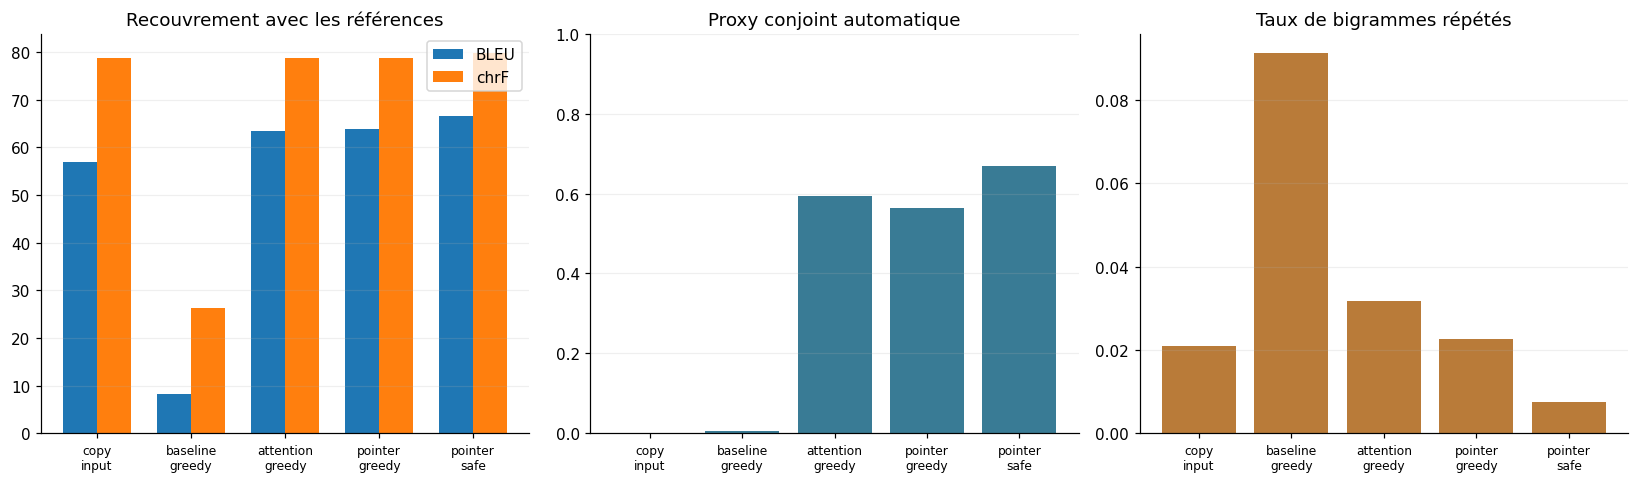

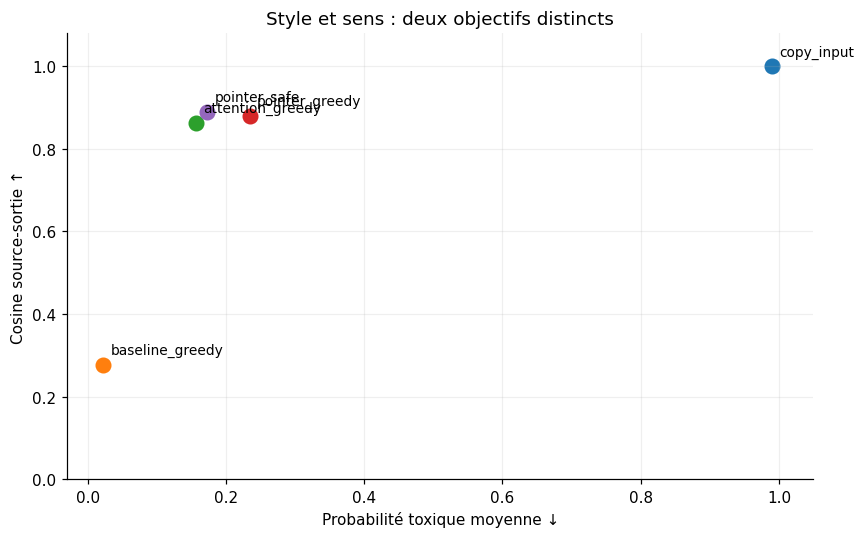

In [63]:
print(RESULT_ORIGIN)
comparison_figures(results)

In [64]:
display(confirmation[['run','n_sources','joint_rate','output_toxicity','semantic_cosine','repeated_bigram_rate']])
base=results.set_index('run').loc['attention_greedy']; final=results.set_index('run').loc[SELECTED]
print(f"Final − attention greedy : chrF {final.chrF-base.chrF:+.2f} ; proxy conjoint {100*(final.joint_rate-base.joint_rate):+.2f} points.")

,run,n_sources,joint_rate,output_toxicity,semantic_cosine,repeated_bigram_rate
0,attention_greedy,1193,0.578374,0.177481,0.872488,0.037720
1,pointer_safe,1193,0.645432,0.170216,0.885066,0.013412


Final − attention greedy : chrF +1.13 ; proxy conjoint +7.46 points.


<a id="part-17"></a>
## 17. Analyse critique des résultats

*Required analysis*

### Évaluation qualitative — Phrases générées

**30 cas, quatre systèmes réellement exécutés** : 20 sources du test de cette exécution sélectionnées par
graine et propriétés de l’entrée (sans examiner les sorties), puis dix diagnostics libres : idiomes,
négations, dates, nombres, noms, entrée longue et phrases neutres. Les diagnostics ne sont pas un test
indépendant et ne servent pas à régler le modèle.

Les références des 20 premiers cas viennent du corpus ; les dix derniers n’ont aucune référence inventée.
Les commentaires automatiques ci-dessous signalent des risques. Les lectures critiques assistées ne
constituent pas une annotation humaine : aucune note de grammaticalité ou précision humaine n’est inventée.
Le pointer est inclus dans la table de scores et dans la table complémentaire ; la grande table montre
baseline, attention et final pour rester lisible.


**Nouveaux contrôles de prudence :** dates et montants dans le même ordre, négations modifiées et sorties anormalement courtes. Ils servent à **signaler** des erreurs possibles, pas à garantir une phrase correcte.

In [65]:
def qualitative_inputs():
    texts,refs=grouped_references(splits['test'])
    # Selection uses INPUT properties only, before generation: no success cherry-picking.
    rng=np.random.default_rng(2027)
    indices=list(rng.choice(len(texts),12,replace=False))
    predicates=[lambda s:len(s.split())<=7,lambda s:len(s.split())>=23,
                lambda s:bool(re.search(r'\d',s)),lambda s:bool(re.search(r"\bnot\b|n't",s)),
                lambda s:bool(re.search(r'\bfuck\w*\b|\bshit\b',s))]
    for predicate in predicates:
        possible=[i for i,t in enumerate(texts) if predicate(t) and i not in indices]
        indices.extend(possible[:1])
    for i in rng.permutation(len(texts)):
        if len(indices)>=20: break
        if i not in indices: indices.append(int(i))
    rows=[{'category':'Test — sélection par entrée','source':texts[i],'references':refs[i],
           'test_index':int(i)} for i in indices]
    diagnostic=[
        ('Idiome','I worked my ass off to finish this report before noon.'),
        ('Négation logique','It would be stupid not to back up these files.'),
        ('Dates','Those fools scheduled the inspection for June 14 instead of June 21.'),
        ('Idiome / plainte','We got screwed when the seller changed the price.'),
        ('Déjà neutre','Please send me the report.'),
        ('Neutre / noms','Alice will meet Daniel at the library tomorrow.'),
        ('Nombres','Your stupid invoice says 35 dollars instead of 3.5 dollars.'),
        ('Négation','Do not delete the backup files.'),
        ('Phrase longue','The support team ignored my complaint for two weeks, and their stupid reply did not explain why the refund was refused.'),
        ('Critique','Your idea is stupid.')]
    rows.extend({'category':cat,'source':text,'references':[],'test_index':None} for cat,text in diagnostic)
    return pd.DataFrame(rows)


In [66]:
qual_inputs=qualitative_inputs()
qual_systems=list(dict.fromkeys(['baseline_greedy','attention_greedy','pointer_greedy',SELECTED]))
qual_table,qual_generation=generate_table(qual_inputs.source.tolist(),qual_inputs.references.tolist(),qual_systems)
qual_metrics,qual_evaluators,qual_flags=assess_table(qual_table,qual_generation)
print('Nouvelles inférences dans ce runtime — diagnostics descriptifs, pas un score de population.')
display(qual_metrics.round(4))

Inférence baseline_greedy : 30 phrases
Inférence attention_greedy : 30 phrases
Inférence pointer_greedy : 30 phrases
Inférence pointer_safe : 30 phrases
Nouvelles inférences dans ce runtime — diagnostics descriptifs, pas un score de population.


,run,n_sources,output_toxicity,semantic_cosine,joint_rate,joint_CI_low,joint_CI_high,repeated_bigram_rate,length_limit_rate,digit_cases,digits_preserved_rate,negation_change_rate,number_order_change_rate,short_output_rate,lost_name_rate
0,baseline_greedy,30,0.0172,0.2539,0.0000,0.0000,0.0000,0.0333,0.0,5,0.0,0.3000,1.0,0.1000,0.0667
1,attention_greedy,30,0.1686,0.8781,0.5333,0.3667,0.7333,0.0333,0.0,5,0.6,0.1000,0.4,0.0667,0.0000
2,pointer_greedy,30,0.3668,0.9292,0.5667,0.4000,0.7667,0.0000,0.0,5,0.6,0.1000,0.4,0.1000,0.0333
3,pointer_safe,30,0.3177,0.9345,0.6000,0.4333,0.7667,0.0000,0.0,5,1.0,0.0333,0.0,0.0333,0.0333


In [67]:
# Lectures critiques des sorties observées : utilisées seulement si le hash entrée+sortie correspond.
# Aucun de ces textes n’est utilisé comme prédiction, référence, donnée d’entraînement ou règle de décodage.
EDITORIAL_NOTES = {}

In [68]:
def show_qualitative(inputs, table, live_evaluators, live_flags):
    import html
    final_ev=live_evaluators[live_evaluators.run.eq(SELECTED)].set_index('index')
    final_flags=live_flags[live_flags.run.eq(SELECTED)].set_index('index')
    for start in range(0,len(inputs),5):
        html_rows=[]
        for i in range(start,min(start+5,len(inputs))):
            row=table.iloc[i]; ev=final_ev.loc[i]; flag=final_flags.loc[i]
            references=json.loads(row.references)
            values=[f'{i+1}. '+row.source, '\n'.join(references) if references else 'Aucune référence — diagnostic libre',
                    row['baseline_greedy'],row['attention_greedy'],row[SELECTED]]
            html_rows.append('<tr>'+''.join('<td>'+html.escape(v).replace('\n','<br>')+'</td>' for v in values)+'</tr>')
            style='baisse du score toxique' if ev.output_toxicity<ev.source_toxicity else 'pas de baisse du score toxique'
            facts='valeurs dans le même ordre' if flag.numbers_in_same_order else 'ALERTE : VALEURS ABSENTES OU RÉORDONNÉES'
            neg='compte de négations inchangé' if not flag.negation_count_changed else 'NÉGATION MODIFIÉE'
            note=(f'{inputs.iloc[i].category} — Style : {style} ({ev.output_toxicity:.3f}). '
                  f'Sens : cosine {ev.semantic_cosine:.3f}, ne prouve pas l’équivalence. '
                  f'Faits : {facts} ; {neg}. '+('ALERTE : sortie très courte. ' if flag.suspicious_truncation else '')+'Grammaire : vérification humaine nécessaire.')
            key=hashlib.sha256((row.source+'\n'+row[SELECTED]).encode()).hexdigest()
            if key in EDITORIAL_NOTES: note+=' Lecture critique assistée : '+EDITORIAL_NOTES[key]
            html_rows.append('<tr><td colspan="5" style="background:#f1f5fa;font-size:12px">'+html.escape(note)+'</td></tr>')
        markup='''<div style="overflow-x:auto;margin:18px 0"><table style="border-collapse:collapse;min-width:1000px;width:100%;table-layout:fixed;font-family:Arial;font-size:13px">
        <thead><tr style="background:#193c62;color:white">'''+''.join('<th style="padding:10px">'+s+'</th>' for s in ['Entrée','Référence(s) du corpus','Baseline','Attention','Modèle final'])+'''</tr></thead><tbody>'''+''.join(html_rows)+'''</tbody></table></div>'''
        markup=markup.replace('<td>','<td style="border:1px solid #d6dee8;padding:9px;vertical-align:top;white-space:normal;overflow-wrap:anywhere">')
        display(HTML(markup))

In [69]:
show_qualitative(qual_inputs,qual_table,qual_evaluators,qual_flags)

In [70]:
display(qual_table[['source','pointer_greedy']].rename(columns={'source':'Entrée','pointer_greedy':'Pointer — inférence actuelle'}))
e=qual_evaluators[qual_evaluators.run.eq(SELECTED)].reset_index(drop=True)
f=qual_flags[qual_flags.run.eq(SELECTED)].reset_index(drop=True)
sensitivity=[]
for tox in [.3,.5]:
    for cosine in [.7,.8,.9]:
        ok=(~f['empty'] & ~f.repeated_bigram & ~f.hit_length_limit & e.output_toxicity.lt(tox) & e.semantic_cosine.ge(cosine))
        sensitivity.append({'seuil toxicité':tox,'seuil cosine':cosine,'proxy conjoint (30 cas)':ok.mean()})
display(pd.DataFrame(sensitivity))
print('Cas satisfaisant le proxy automatique :',(f.joint_proxy.to_numpy().nonzero()[0]+1).tolist())
print('Cas ne le satisfaisant pas :',((~f.joint_proxy).to_numpy().nonzero()[0]+1).tolist())
print('Ces groupes ne sont PAS des succès/échecs humains certifiés.')

,Entrée,Pointer — inférence actuelle
0,leave us awful liberals alone .,leave us awful liberals alone
1,it was really shit bearing in mind i have seen...,it was really bad bearing in mind i have seen ...
2,stop the idiocy for gawd sakes .,stop the idiocy for gawd sakes
3,does nobody here actually read the fucking art...,does nobody here actually read the article?
4,"whoever hit & run my car , karmas a bitch ! ! !","whoever hit & run my car, karmasant!"
5,"president trump , who is an imbecile , had no ...","president trump, who is not good enough what w..."
6,shut up ! its really hot as fuck outside and i...,it's really hot and i just came all the way fr...
7,holy shit that is gonna kick all asses ! ! ! !,that is gonna kick all
8,"bernie sanders isn 't obama , not unless he st...","bernie sanders isn't obama, not unless he star..."
9,$50 barrel oil for the next * * 27 years * * y...,$50 barrel oil for the next * 27 years * * you...


,seuil toxicité,seuil cosine,proxy conjoint (30 cas)
0,0.3,0.7,0.666667
1,0.3,0.8,0.600000
2,0.3,0.9,0.400000
3,0.5,0.7,0.666667
4,0.5,0.8,0.600000
5,0.5,0.9,0.400000


Cas satisfaisant le proxy automatique : [2, 4, 5, 6, 7, 9, 10, 12, 13, 16, 17, 18, 19, 21, 25, 26, 28, 29]
Cas ne le satisfaisant pas : [1, 3, 8, 11, 14, 15, 20, 22, 23, 24, 27, 30]
Ces groupes ne sont PAS des succès/échecs humains certifiés.


In [71]:
@torch.inference_mode()
def show_attention(text):
    # Teacher-free greedy trace; explicitly distinct from the final beam output.
    model=models[SELECTED.split('_',1)[0]]
    if model.variant == 'baseline':
        print('La baseline sélectionnée ne possède pas d’attention ; illustration avec le modèle attention.')
        model=models['attention']
    source=torch.tensor([tokenizer.encode(normalize(text))+[EOS]],device=DEVICE)
    enc,state=model.encoder(source,torch.tensor([source.size(1)]))
    previous=torch.tensor([[BOS]],device=DEVICE); rows=[]; ids=[]; gates=[]
    for _ in range(config['max_generation']):
        lp,state,attn,gate=model.decoder(previous,state,enc,source)
        scores=lp[0,0].clone(); scores[PAD]=scores[BOS]=-float('inf')
        token=int(scores.argmax()); rows.append(attn[0,0].cpu().numpy()); ids.append(token)
        if gate is not None: gates.append(float(gate[0,0,0]))
        previous=torch.tensor([[token]],device=DEVICE)
        if token==EOS: break
    fig,ax=plt.subplots(figsize=(max(8,source.size(1)*.35),max(3,len(rows)*.3)))
    im=ax.imshow(rows,aspect='auto',cmap='Blues')
    ax.set_xticks(range(source.size(1)),[tokenizer.id_to_piece(int(x)) for x in source[0]],rotation=65,ha='right',fontsize=8)
    ax.set_yticks(range(len(ids)),[tokenizer.id_to_piece(x) for x in ids],fontsize=8)
    ax.set(title='Attention réelle — trace greedy sans référence',xlabel='Sous-mots source',ylabel='Sous-mots générés')
    fig.colorbar(im,ax=ax,label='Poids d’attention'); plt.tight_layout(); plt.show()
    print('Sortie greedy de cette trace :',tokenizer.decode([x for x in ids if x!=EOS]))

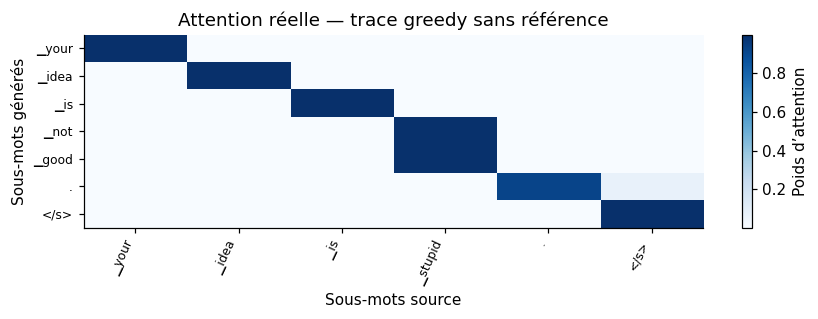

Sortie greedy de cette trace : your idea is not good.


In [72]:
show_attention('Your idea is stupid.')

**Analyse des mécanismes d’erreur.** Le corpus est petit et contient des références hétérogènes.
Supprimer un mot offensant peut créer un trou syntaxique ; copier peut conserver l’insulte.
Les sous-mots et la limite de génération ne garantissent pas les nombres. Ni cosine élevée ni attention
visuellement plausible ne prouvent une implication logique correcte. La carte montre une trace greedy,
et ne prétend pas expliquer la sortie beam comme une preuve causale.

Il faudrait une annotation humaine aveugle style/sens/grammaire/faits, plusieurs graines et un nouveau
test pour conclure plus solidement. Une augmentation ciblée ou un mécanisme de copie d’entités reste
une piste future, pas une amélioration exécutée ici.

### Lecture qualitative de générations observées

Les cas suivants proviennent **des sorties effectivement enregistrées dans ce notebook** (tableau des 30 inférences de la section 17). Ils illustrent à la fois les réussites et les limites du système final sélectionné ; les formulations ci-dessous ne sont pas des corrections ajoutées au décodeur.

| Entrée | Génération réelle du modèle final | Analyse |
|---|---|---|
| `Your idea is stupid.` | `Your idea is bad.` | **Réussite relative :** formulation moins offensante, tout en conservant une critique négative. |
| `Please send me the report.` | `Please send me the report.` | **Conservation utile :** la phrase déjà neutre reste inchangée. |
| `I worked my ass off to finish this report before noon.` | `I worked my se off to finish this report before noon.` | **Échec grammatical :** l’expression idiomatique est brisée et le sous-mot produit n’est pas une reformulation anglaise correcte. |
| `Those fools scheduled the inspection for June 14 instead of June 21.` | `Those fools scheduled the inspection for June 14 instead of je 21.` | **Échec mixte :** expression insultante conservée et mois altéré ; les chiffres seuls ne suffisent pas à valider les faits. |
| `We got screwed when the seller changed the price.` | `We got screwed when the seller changed the price.` | **Échec de détoxification :** copie exacte d’une plainte contenant une expression vulgaire. |

**Interprétation.** Le modèle est capable de changements lexicaux simples et de conserver des phrases déjà neutres ; il échoue plus souvent lorsqu’une expression doit être reformulée dans son ensemble ou lorsqu’une contrainte factuelle et stylistique doit être satisfaite simultanément. Les métriques automatiques (BLEU, chrF, similarité, score de toxicité) sont utiles pour comparer les systèmes, mais **ne garantissent ni la grammaticalité ni la fidélité des faits**. Ces exemples ne mesurent pas un taux global d’erreur ; les résultats quantitatifs figurent dans la section 15 et l’évaluation humaine reste à réaliser.


<a id="part-18"></a>
## 18. Synthèse du projet

*Expected project structure*

Le projet contient l'introduction (1–4), les données et la représentation (5–7), le code des architectures (8–11), l'entraînement (12), le décodage (13–14), les résultats (15–17), puis la synthèse, la vérification et la conclusion (18–20).

**Interprétation attendue :** confronter les métriques quantitatives aux phrases générées réellement. La copie peut préserver des informations mais également des insultes. La diminution de la loss ne prouve pas une détoxification correcte.


<a id="part-19"></a>
## 19. Vérification des exigences

*Deliverables*

### Checklist de conformité intégrée
Le code, le texte scientifique, les figures, résultats et éléments de démonstration sont tous dans ce
notebook. L’énoncé mentionne aussi un rapport et une présentation séparés ; **à votre demande, ils sont
regroupés ici et aucun fichier distinct n’est livré**. Cette adaptation de format n’est pas présentée
comme une dispense déjà approuvée par l’enseignante.

| Exigence | Preuve dans le notebook |
|---|---|
| 1–2. Objectif et tâche | Formulation conditionnelle et détoxification |
| 3–4. Architecture de zéro | Classes PyTorch visibles, les trois architectures et leurs checkpoints calculés dans cette session |
| 5–7. Corpus, split, représentation | Téléchargement réel, empreinte, disjonction, BPE, PAD/UNK/BOS/EOS |
| 8–11. Encoder, decoder, teacher forcing, attention | Équations, code, formes, distributions et porte pointer |
| 12. Entraînement | Boucles, hyperparamètres, reprise, meilleures époques et courbes |
| 13–14. Inférence et décodage | Greedy, beam, expérience de reclassement documentée |
| 15–16. Évaluation et baseline | BLEU, chrF, NLL/PPL, style, sens, répétitions, proxy conjoint |
| 17. Analyse | 30 nouvelles inférences, vrais échecs, absence de références inventées |
| 18–19. Structure et livraison | Synthèse scientifique, figures et démonstration dans ce fichier unique |
| 20. Limites | Une graine, test distinct, avec limites liées au protocole, aucune annotation humaine, erreurs factuelles |

La conformité technique ci-dessous est contrôlée par des assertions ; elle ne valide pas la qualité humaine.


In [73]:
def smoke_tests(config, vocab_size, device):
    # Structural checks for all variants, independent of ParaDetox.
    small = {**config, "embedding_dim": 8, "hidden_dim": 16, "dropout": .1}
    for variant in ["baseline", "attention", "pointer"]:
        seed_everything(7)
        model = RewriteModel(vocab_size, small, variant).to(device)
        source = torch.tensor([[4, 5, EOS], [6, EOS, PAD]], device=device)
        lengths = torch.tensor([3, 2])
        target = torch.tensor([[BOS, 4, EOS], [BOS, 6, EOS]], device=device)
        model.eval()
        log_probs = model(source, lengths, target[:, :-1])
        assert log_probs.shape == (2, 2, vocab_size)
        assert torch.isfinite(log_probs).all()
        assert torch.allclose(log_probs.exp().sum(-1), torch.ones(2, 2, device=device), atol=1e-5)
        enc, state = model.encoder(source, lengths)
        _, _, weights, gate = model.decoder(target[:, :-1], state, enc, source)
        if weights is not None:
            assert (weights[1, :, 2] == 0).all(), "Le PAD reçoit de l’attention."
        if gate is not None:
            assert ((gate >= 0) & (gate <= 1)).all()
        # Added padding must not change valid predictions.
        extended = nn.functional.pad(source, (0, 2), value=PAD)
        assert torch.allclose(
            log_probs, model(extended, lengths, target[:, :-1]), atol=1e-5)
        model.train()
        if variant != 'baseline':
            sampled = model(source, lengths, target[:, :-1], teacher_forcing_ratio=.75)
            assert torch.isfinite(sampled).all()
            assert sampled.shape == log_probs.shape
        loss = token_loss(model(source, lengths, target[:, :-1]), target[:, 1:]) / 4
        loss.backward()
        assert all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None)
        # Loss ignores additional PAD target positions.
        extra_probs = torch.cat([log_probs, log_probs[:, :1]], dim=1)
        padded_gold = nn.functional.pad(target[:, 1:], (0, 1), value=PAD)
        assert torch.allclose(token_loss(log_probs, target[:, 1:]),
                              token_loss(extra_probs, padded_gold))
        print("Tests structurels réussis :", variant)
    if device.type == "cuda":
        torch.cuda.empty_cache()

In [74]:
smoke_tests(config,tokenizer.get_piece_size(),DEVICE)
for name,model in models.items():
    restored,_=load_run(model_paths[name],tokenizer,DEVICE)
    assert all(torch.equal(v,restored.state_dict()[k]) for k,v in model.state_dict().items())
assert len(qual_table)==30 and not qual_table[qual_systems].isna().any().any()
assert all(cp['tokenizer_hash']==hashlib.sha256(tokenizer.serialized_model_proto()).hexdigest() for cp in checkpoints.values())
print('Contrôles réussis : formes, probabilités, masque PAD, gradients, chargement des poids et 30 générations par système.')

Tests structurels réussis : baseline
Tests structurels réussis : attention
Tests structurels réussis : pointer
Contrôles réussis : formes, probabilités, masque PAD, gradients, chargement des poids et 30 générations par système.


### Tests unitaires additionnels du classement
Ces assertions portent sur des **candidats synthétiques** afin de vérifier que les protections fonctionnent. Elles ne sont ni des exemples d'entraînement ni une preuve de meilleure génération réelle.

In [75]:
assert select_candidate('John paid $250', [
    ('john paid $150', -1.,False,0),
    ('john paid $250', -3.,False,0)])['output'].lower().startswith('john paid $250')
assert select_candidate('Deadline from March 12 to March 19', [
    ('deadline from march 19', -1.,False,0),
    ('deadline from march 12 to march 19', -3.,False,0)])['output'].lower().find('12') >= 0
assert restore_formatting('John visited Paris.', 'john visited paris') == 'John visited Paris.'
assert select_candidate('John paid $250', [('john paid $150',-1.,False,0)])['needs_review']
print('Tests déterministes V3 : préservation et alertes OK.')

Tests déterministes V3 : préservation et alertes OK.


<a id="part-20"></a>
## 20. Limites et conclusions

*Important restriction*

Ces modèles construits de zéro sont des systèmes pédagogiques : ils ne garantissent ni grammaticalité, ni conservation du sens, ni absence de toxicité. Les négations, expressions idiomatiques, nombres et dates sont particulièrement difficiles. Les métriques automatiques ne remplacent pas une évaluation humaine et la comparaison repose sur une seule graine d'entraînement.

**Traçabilité :** les figures et les phrases présentées sont recalculées pendant cette exécution. La validation sert au choix du système ; les observations sur le test doivent être interprétées avec prudence. Les données et les évaluateurs sont téléchargés depuis leurs sources publiques.


**Version corrigée :** le reranking factuel est maintenant un candidat expérimental. Il n’est conservé que s’il est meilleur selon la validation et les garde-fous définis à l’avance. Les contrôles des dates et négations restent des heuristiques ; ils ne garantissent pas zéro erreur.

In [76]:
import platform
display(pd.Series({'Python':platform.python_version(),'PyTorch':torch.__version__,'NumPy':np.__version__,
                  'pandas':pd.__version__,'dispositif':str(DEVICE),'entraînement from scratch':True,
                  'origine des scores de population':RESULT_ORIGIN,'nombre de nouvelles phrases comparées':len(qual_table)}))


,0
Python,3.13.16
PyTorch,2.11.0+cu130
NumPy,2.1.3
pandas,2.2.3
dispositif,cuda
entraînement from scratch,True
origine des scores de population,Mesures recalculées à partir des modèles entra...
nombre de nouvelles phrases comparées,30


## Démonstration — Tester ParaDetox avec mes propres phrases
Modifier `text` ou la liste `phrases`, puis exécuter la dernière cellule. Le modèle final et le décodage
sélectionnés sont déjà en mémoire ; aucune référence ni réentraînement. Les sorties sont brutes, sans
correction manuelle. Le petit formulaire est facultatif : l’appel Python fonctionne aussi sans widget.

In [77]:
def detoxify(text, detailed=False):
    """Sortie neuronale, avec alertes plutôt que corrections cachées."""
    if not isinstance(text,str) or not text.strip():
        raise ValueError('Entrer une phrase anglaise non vide.')
    info=predict_system(SELECTED,[text])[0]
    if not info.get('output','').strip():
        info['needs_review']=True
        info['warning']='sortie vide'
    if 'needs_review' not in info:
        flags=output_diagnostics(text,info['output'],info.get('hit_length_limit',False))
        flagged=(flags['empty'] or flags['names_lost'] or not flags['numbers_in_same_order']
                 or flags['suspicious_truncation'] or flags['unseen_generated_words']>0)
        info['needs_review']=bool(flagged)
        info['warning']='Contrôles automatiques : ' + ', '.join(
            k for k,v in flags.items() if k in ('names_lost','suspicious_truncation','empty') and v)
    return info if detailed else info['output']

In [78]:
try:
    import ipywidgets as widgets
    input_box=widgets.Textarea(value='Your idea is stupid.',description='Anglais :',layout=widgets.Layout(width='95%'))
    button=widgets.Button(description='Détoxifier',button_style='primary')
    widget_output=widgets.Output()
    def on_generate(_):
        with widget_output:
            widget_output.clear_output()
            try: print(detoxify(input_box.value))
            except Exception as error: print(type(error).__name__+': '+str(error))
    button.on_click(on_generate)
    display(input_box,button,widget_output)
except ImportError:
    print('Widget indisponible ; utiliser la cellule Python ci-dessous.')

Textarea(value='Your idea is stupid.', description='Anglais :', layout=Layout(width='95%'))

Button(button_style='primary', description='Détoxifier', style=ButtonStyle())

Output()

In [79]:
text = "Your idea is stupid."
detoxified = detoxify(text)
print("Original:", text)
print("Detoxified:", detoxified)

phrases = [
    "Please send me the report.",
    "This stupid system deleted 15 files even though I only selected 3.",
    "Those fools scheduled the inspection for June 14 instead of June 21.",
]
display(pd.DataFrame({'Original':phrases,'Detoxified':[detoxify(p) for p in phrases]}))

Original: Your idea is stupid.
Detoxified: Your idea is bad.


,Original,Detoxified
0,Please send me the report.,Please send me the report.
1,This stupid system deleted 15 files even thoug...,This system deleted 15 files even though i onl...
2,Those fools scheduled the inspection for June ...,Those fools scheduled the inspection for June ...


### Batterie diagnostique — 60 phrases inédites à vérifier
Les phrases ci-dessous servent à **diagnostiquer** le modèle ; elles ne sont pas des références d'entraînement ni un test statistiquement indépendant. Le tableau est produit uniquement par `detoxify()` (inférence réelle).

In [80]:
test_groups = {}

In [81]:
test_groups['01 - Insultes simples'] = ['Your idea is stupid.', 'Stop acting like an idiot.', 'This explanation is garbage.', 'What a dumb decision!', 'You are completely useless.', 'These idiots ruined the meeting.']

In [82]:
test_groups['02 - Expressions vulgaires'] = ['This damn computer keeps crashing.', 'What the hell are you doing?', 'This is a shitty situation.', "I'm sick of this crap.", 'That concert was fucking amazing.', 'We got screwed by the seller.']

In [83]:
test_groups['03 - Expressions idiomatiques'] = ['I worked my ass off to finish this report.', 'He screwed up the entire project.', 'They are full of crap.', 'This decision is a pain in the ass.', "She doesn't give a damn about the rules.", 'That idiot threw me under the bus.']

In [84]:
test_groups['04 - Negations et logique'] = ['It would be stupid not to back up your files.', "Don't be an idiot and ignore the warning.", "I don't think your stupid idea will work.", "It's not stupid to ask for help.", 'Only a fool would ignore these instructions.', 'This is not a bad idea, but your explanation sucks.']

In [85]:
test_groups['05 - Dates et nombres'] = ['Those fools changed the deadline from March 12 to March 19.', 'This stupid system deleted 15 files instead of 3.', 'The idiots scheduled the meeting at 9 AM instead of 11 AM.', 'I paid $250 for this damn phone.', 'Those morons sent 12 packages to the wrong address.', 'The stupid invoice says $180 instead of $108.']

In [86]:
test_groups['06 - Phrases longues'] = ['These idiots changed the delivery date without informing anyone, and now the entire team has to reorganize its schedule.', 'This stupid application keeps crashing whenever I try to upload a document larger than 10 MB.', 'The support team gave me a ridiculous explanation even though I had already provided all the necessary information.', 'I spent three hours fixing this damn report because the system deleted several important sections.', 'Those fools approved the budget without checking the numbers, which caused major problems for the project.', 'This terrible service made me wait for two hours and then cancelled my appointment without any explanation.']

In [87]:
test_groups['07 - Phrases deja neutres'] = ['Please send me the report before Friday.', 'The meeting has been moved from 9 AM to 11 AM.', 'I disagree with your conclusion.', 'Could you explain why the delivery was delayed?', 'The system deleted three files by mistake.', 'I would prefer another solution.']

In [88]:
test_groups['08 - Toxicite contextuelle'] = ['Your argument makes no sense because you ignored the evidence.', "I can't believe how incompetent this team is.", "You clearly have no idea what you're talking about.", 'The manager handled this situation terribly.', 'This company treats its customers like idiots.', 'Nobody should trust such a dishonest person.']

In [89]:
test_groups['09 - Sens et sentiment'] = ['That movie was damn good!', 'This is insanely beautiful.', 'I hate how badly this feature works.', 'You did a hell of a good job.', 'The results are absolutely terrible.', 'This brilliant idea was ruined by stupid implementation.']

In [90]:
test_groups['10 - Cas difficiles'] = ['I would be an idiot not to accept this opportunity.', 'Those idiots sent the files to John instead of James.', 'This stupid program deleted my backup but kept the corrupted version.', "Don't screw this up again because we only have one chance.", 'The manager said the stupid system failed, not that the employees were responsible.', 'Your ridiculous decision cost us $1,500 and delayed the launch by three weeks.']

In [91]:
test_rows = [{'Category': cat, 'Original': s}
             for cat, phrases in test_groups.items() for s in phrases]
diagnostic_results = pd.DataFrame(test_rows)
assert len(diagnostic_results) == 60
print('Phrases à évaluer :', len(diagnostic_results))

Phrases à évaluer : 60


In [92]:
# Inférence réelle : aucune référence n'est fournie au modèle.
reports = [detoxify(s, detailed=True) for s in diagnostic_results.Original]
diagnostic_results['Detoxified'] = [r['output'] for r in reports]
diagnostic_results['Needs_review'] = [r['needs_review'] for r in reports]
diagnostic_results['Warning'] = [r.get('warning','') for r in reports]
display(diagnostic_results[['Category','Original','Detoxified','Needs_review','Warning']])

,Category,Original,Detoxified,Needs_review,Warning
0,01 - Insultes simples,Your idea is stupid.,Your idea is bad.,False,
1,01 - Insultes simples,Stop acting like an idiot.,Stop acting like an.,False,
2,01 - Insultes simples,This explanation is garbage.,This explanation is bad.,False,
3,01 - Insultes simples,What a dumb decision!,What an decision!,False,
4,01 - Insultes simples,You are completely useless.,You are completely useless.,False,
5,01 - Insultes simples,These idiots ruined the meeting.,These ruin ruined the meeting.,False,
6,02 - Expressions vulgaires,This damn computer keeps crashing.,This computer keeps crashing.,False,
7,02 - Expressions vulgaires,What the hell are you doing?,What are you doing?,False,
8,02 - Expressions vulgaires,This is a shitty situation.,This is a bad situation.,False,
9,02 - Expressions vulgaires,I'm sick of this crap.,I'm sick of this.,False,


In [93]:
diagnostic_flags = pd.DataFrame([
    output_diagnostics(s, t) for s, t in zip(diagnostic_results.Original, diagnostic_results.Detoxified)
])
diagnostic_results = pd.concat([diagnostic_results, diagnostic_flags], axis=1)
diagnostic_results.to_csv('paradetox_60_tests.csv', index=False)
print('Fichier créé : paradetox_60_tests.csv')

Fichier créé : paradetox_60_tests.csv


In [94]:
cols = ['Category','digits_preserved','numbers_in_same_order',
        'names_lost','negation_count_changed','suspicious_truncation',
        'repeated_bigram','unseen_generated_words']
display(diagnostic_results[cols].groupby('Category').mean(numeric_only=True).round(3))
problem_cases = diagnostic_results[diagnostic_results.Needs_review | (
    diagnostic_results.source_has_digits & ~diagnostic_results.numbers_in_same_order) |
    diagnostic_results.names_lost | diagnostic_results.suspicious_truncation]
display(problem_cases[['Category','Original','Detoxified','Warning']])
print('Cas à examiner manuellement :',len(problem_cases),'/',len(diagnostic_results))

,digits_preserved,numbers_in_same_order,names_lost,negation_count_changed,suspicious_truncation,repeated_bigram,unseen_generated_words
Category,,,,,,,
01 - Insultes simples,1.0,1.0,0.000,0.0,0.0,0.0,0.0
02 - Expressions vulgaires,1.0,1.0,0.000,0.0,0.0,0.0,0.0
03 - Expressions idiomatiques,1.0,1.0,0.000,0.0,0.0,0.0,0.0
04 - Negations et logique,1.0,1.0,0.000,0.0,0.0,0.0,0.0
05 - Dates et nombres,1.0,1.0,0.167,0.0,0.0,0.0,0.0
06 - Phrases longues,1.0,1.0,0.000,0.0,0.0,0.0,0.0
07 - Phrases deja neutres,1.0,1.0,0.000,0.0,0.0,0.0,0.0
08 - Toxicite contextuelle,1.0,1.0,0.000,0.0,0.0,0.0,0.0
09 - Sens et sentiment,1.0,1.0,0.000,0.0,0.0,0.0,0.0


,Category,Original,Detoxified,Warning
24,05 - Dates et nombres,Those fools changed the deadline from March 12...,Those fools changed the deadline from March 12...,noms manquants


Cas à examiner manuellement : 1 / 60


**Interprétation.** Une copie inchangée peut être correcte pour une phrase déjà neutre mais échouer sur une phrase toxique. Une phrase sans chiffres modifiés peut tout de même présenter un contresens. Compléter manuellement les colonnes `sens`, `toxicité`, `grammaire` pour juger les sorties ; aucune correction n’est intégrée au modèle à partir de ces 60 diagnostics.

In [95]:
# Tableau facultatif d'annotation humaine, à remplir manuellement.
human_review = diagnostic_results[['Category','Original','Detoxified']].copy()
for criterion in ['Toxicite_reduite','Sens_preserve','Grammaire_correcte']:
    human_review[criterion] = pd.NA
human_review.to_csv('paradetox_annotation_humaine_a_remplir.csv', index=False)
print('Annotations humaines : à remplir (aucune valeur inventée).')

Annotations humaines : à remplir (aucune valeur inventée).


### Vérification supplémentaire — 40 phrases distinctes

Ces exemples ne sont ni insérés dans le corpus d’entraînement, ni utilisés pour choisir les hyperparamètres. Ils révèlent d’éventuels échecs sur les entités, les expressions, les négations et les phrases neutres. Les corrections doivent être **mesurées après exécution**.

In [96]:
EXTRA_TEST_GROUPS = {}

In [97]:
EXTRA_TEST_GROUPS['Entités et faits'] = ['Those idiots moved the conference from April 18 to April 25 in Lyon.', 'This awful service charged Emma $79 twice on October 3.', 'The stupid report says 18.5% instead of 15.8%.', 'Those fools sent 42 boxes to Madrid rather than Lisbon.', 'This damn device stopped working at 6:30 PM on Tuesday.', 'The incompetent clerk mixed up invoice 1042 and invoice 1402.', 'That stupid app deleted my files from 2022, not 2023.', 'The idiot technician gave Sarah the wrong access code.', 'We paid €125 on May 5 and €375 on May 12, damn it.', 'The useless system shipped 3 monitors instead of 13.']

In [98]:
EXTRA_TEST_GROUPS['Expressions complètes'] = ['She worked her ass off to prepare the presentation.', 'Do not screw around with the safety instructions.', 'They screwed us over after signing the contract.', 'This broken interface is driving me nuts.', 'What a load of crap that excuse is.', 'He is talking out of his ass again.', 'I had to bust my ass to finish by midnight.', 'The whole plan went to hell after the update.', 'I am fed up with their bullshit excuses.', 'She was pissed off when the reservation disappeared.']

In [99]:
EXTRA_TEST_GROUPS['Négation et raisonnement'] = ['It is not foolish to disagree with the manager.', "Don't be stupid enough to disable the only backup.", 'It would be idiotic not to check the invoice.', 'I did not say the stupid manager was responsible.', 'Not every terrible decision is irreversible.', "I can't ignore their ridiculous proposal, but I won't approve it.", "Nobody is saying you shouldn't ask for help.", 'The dumb software did not lose any files this time.', 'I dislike this crappy tool, but it has not failed yet.', 'It is stupid to believe that nobody can make mistakes.']

In [100]:
EXTRA_TEST_GROUPS['Neutres et phrases longues'] = ['Olivia sent the completed report to Daniel yesterday.', 'The price decreased from $950 to $905.', 'Please do not remove the backup folder.', 'We will meet at 8:45 AM on November 9.', 'This method is less effective than the previous one.', 'I appreciate the helpful feedback you provided.', 'My package was delivered to the wrong building.', 'The website is slow, but I can still complete my work.', 'The support agent explained the refund policy clearly.', 'Although the system was updated twice, the important files remained untouched.']

In [101]:
extra_rows=[{'Category':cat,'Original':x} for cat,ss in EXTRA_TEST_GROUPS.items() for x in ss]
extra_results=pd.DataFrame(extra_rows)
assert len(extra_results)==40
extra_reports=[detoxify(x,detailed=True) for x in extra_results.Original]
extra_results['Detoxified']=[r['output'] for r in extra_reports]
extra_results['Needs_review']=[r['needs_review'] for r in extra_reports]
extra_results['Warning']=[r.get('warning','') for r in extra_reports]
display(extra_results)
extra_results.to_csv('paradetox_40_nouveaux_tests.csv',index=False)
print('À examiner :',sum(extra_results.Needs_review),'sur 40 nouvelles phrases')

,Category,Original,Detoxified,Needs_review,Warning
0,Entités et faits,Those idiots moved the conference from April 1...,Those mo moved the conference from April 18 to...,True,noms manquants
1,Entités et faits,This awful service charged Emma $79 twice on O...,This awful service charged Emma $79 twice on O...,False,
2,Entités et faits,The stupid report says 18.5% instead of 15.8%.,The stupid report says 18.5% instead of 15.,True,nombres modifiés; qualité linguistique incertaine
3,Entités et faits,Those fools sent 42 boxes to Madrid rather tha...,Those fools sent 42 boxes to Madrid rather tha...,False,
4,Entités et faits,This damn device stopped working at 6:30 PM on...,This device stopped working at 6:30 pm on Tues...,False,
5,Entités et faits,The incompetent clerk mixed up invoice 1042 an...,The incompetent clerk mixed up invoice 1042 an...,False,
6,Entités et faits,"That stupid app deleted my files from 2022, no...","That app deleted my files from 2022, not023.",True,nombres modifiés; qualité linguistique incertaine
7,Entités et faits,The idiot technician gave Sarah the wrong acce...,The idiot technician gave Sarah the wrong acce...,False,
8,Entités et faits,"We paid €125 on May 5 and €375 on May 12, damn...","We paid ⁇ 1 on May 5 and ⁇ 375 on May 12, it.",True,nombres modifiés; tokens inconnus; qualité lin...
9,Entités et faits,The useless system shipped 3 monitors instead ...,The useless system shipped 3 monitors instead ...,False,


À examiner : 4 sur 40 nouvelles phrases


**Limite** : un avertissement automatique peut manquer une faute grammaticale ou sémantique. Les 100 phrases nécessitent une lecture humaine. Une absence d'alerte ne signifie pas « parfaite ».